# Reproducible Source-Area Workflow

Focused workflow for the main product: **source-area cells and polygons**.

This notebook keeps the code simple and writes intermediate outputs so each stage can be checked later. Lithology/Dunne polygon interpretation is intentionally kept separate from this main source-area pipeline.

## 1. Setup

Inputs used here:

- DEM from `config/montecito.yaml`
- DoD / DEM difference raster from Downloads
- Physical parameters from `config/montecito.yaml`
- Monte Carlo sampling for `C`

Outputs are written to a dedicated folder inside the configured output directory.

In [2]:
from pathlib import Path
import sys

import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from rasterio.features import shapes
from shapely.geometry import shape

# Find repo root whether notebook is run from repo root or notebooks/
REPO = Path.cwd()
if not (REPO / "src").exists():
    REPO = REPO.parent

sys.path.insert(0, str(REPO / "src"))

from pci_source_zones.config import load_config, output_path
from pci_source_zones.physics.terrain import prepare_terrain
from pci_source_zones.inputs import read_raster, write_raster
from pci_source_zones.physics.c_model import modeled_threshold_c

cfg = load_config(REPO / "config" / "montecito.yaml")

OUT = Path(cfg["paths"]["output_dir"]) / "source_area_workflow"
OUT.mkdir(parents=True, exist_ok=True)

DOD_PATH = Path("/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated.tif")
DOD_THRESHOLD = -0.01
TOP_PERCENT_VALUES = [5, 10, 20, 30, 50, 70]

print("repo:", REPO)
print("outputs:", OUT)
print("DoD:", DOD_PATH)

repo: /home/abdullah/pci-source-zones
outputs: /mnt/c/Users/amehedi/Downloads/source_area_workflow
DoD: /mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated.tif


## 2. Terrain Forcing

Compute or load:

`G = aS^alpha`

where `a` is specific catchment area, `S` is slope, and `alpha` is fixed in the config.

In [3]:
g_path = output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif")

if not g_path.exists():
    print("Preparing terrain from DEM...")
    prepare_terrain(cfg)
else:
    print("Using existing G raster:", g_path)

G, profile = read_raster(g_path)
valid = np.isfinite(G)
cell_area_m2 = abs(profile["transform"].a * profile["transform"].e)

print("valid cells:", int(valid.sum()))
print("cell area m2:", cell_area_m2)
print("G min/mean/max:", float(np.nanmin(G)), float(np.nanmean(G)), float(np.nanmax(G)))

Using existing G raster: /mnt/c/Users/amehedi/Downloads/topographic_driving_index.tif
valid cells: 579712
cell area m2: 100.0
G min/mean/max: 0.0 261.84342867141896 1108000.875


## 3. C Distribution

`C` is the modeled resistance threshold. We sample `d50`, `na`, and runoff `r`, then compute one `C` value for each sample.

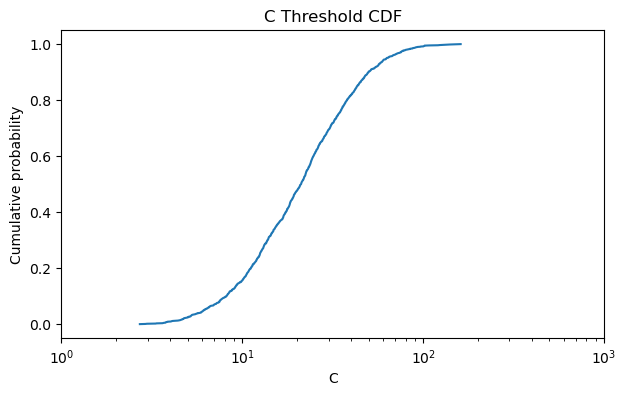

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/c_samples.csv
C min/mean/median/max: 2.715374629992217 26.10574735380302 21.148365686516737 161.39092986695303


In [4]:
n_samples = int(cfg["monte_carlo"].get("n_samples", 1500))
seed = int(cfg["monte_carlo"].get("seed", 42))
rng = np.random.default_rng(seed)

# d50 lognormal with mean 2.0 mm and sd 0.48 mm
d50_mean = 2.0
d50_sd = 0.48
sigma2 = np.log(1 + (d50_sd / d50_mean) ** 2)
mu = np.log(d50_mean) - 0.5 * sigma2
d50_mm = rng.lognormal(mu, np.sqrt(sigma2), n_samples)

# added roughness and runoff ranges
na = rng.uniform(0.015, 0.10, n_samples)
r_mm_hr = rng.uniform(15, 55, n_samples)

C = []
for d50_i, na_i, r_i in zip(d50_mm, na, r_mm_hr):
    c_i = modeled_threshold_c(
        d50_i / 1000,
        na_i,
        r_i / 1000 / 3600,
        cfg["parameters"],
    )
    C.append(float(c_i))

C = np.array(C)
C_sorted = np.sort(C)
C_cdf = np.arange(1, len(C_sorted) + 1) / len(C_sorted)

c_table = pd.DataFrame({"d50_mm": d50_mm, "na": na, "r_mm_hr": r_mm_hr, "C": C})
c_table.to_csv(OUT / "c_samples.csv", index=False)

plt.figure(figsize=(7, 4))
plt.plot(C_sorted, C_cdf)
plt.xscale("log")
plt.xlim(1, 1000)
plt.xlabel("C")
plt.ylabel("Cumulative probability")
plt.title("C Threshold CDF")
plt.show()

print("saved:", OUT / "c_samples.csv")
print("C min/mean/median/max:", C.min(), C.mean(), np.median(C), C.max())

## 4. PCI Map

Convert every terrain cell to initiation probability:

`PCI = P(C <= G)`

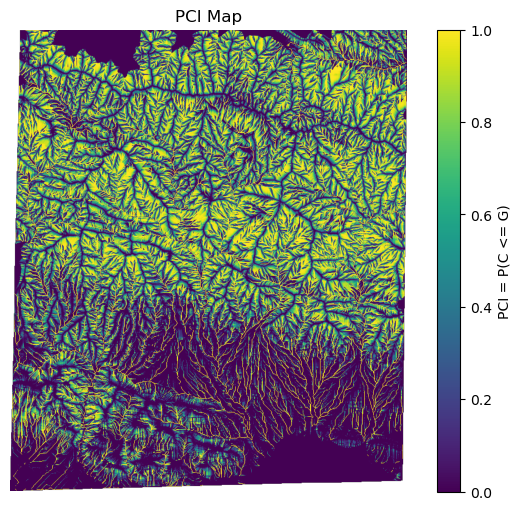

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/pci_from_c_cdf.tif
PCI min/mean/max: 0.0 0.37795189023017883 1.0


In [5]:
pci = np.full(G.shape, np.nan, dtype="float32")

pci[valid] = np.searchsorted(
    C_sorted,
    G[valid],
    side="right",
) / len(C_sorted)

pci_path = OUT / "pci_from_c_cdf.tif"
write_raster(pci_path, pci, profile)

plt.figure(figsize=(8, 6))
plt.imshow(pci, vmin=0, vmax=1)
plt.colorbar(label="PCI = P(C <= G)")
plt.title("PCI Map")
plt.axis("off")
plt.show()

print("saved:", pci_path)
print("PCI min/mean/max:", float(np.nanmin(pci)), float(np.nanmean(pci)), float(np.nanmax(pci)))

## 5. Observed Erosion Mask

Use DoD as observed erosion evidence. Here we keep cells where:

`DoD < -0.277 m`

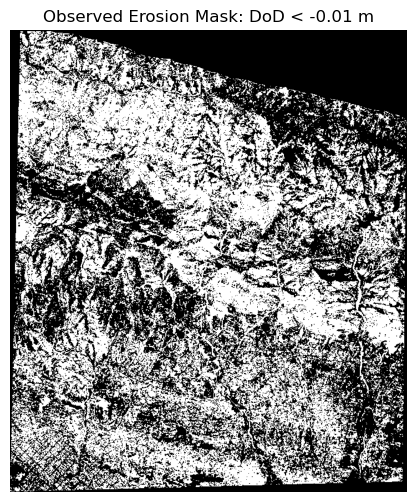

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/erosion_mask_dod_lt_minus_0p277.tif
erosion pixels: 286391
erosion area km2: 28.6391


In [6]:
with rasterio.open(DOD_PATH) as src:
    dod = src.read(1)
    dod_nodata = src.nodata

if dod_nodata is None:
    dod_valid = np.isfinite(dod)
else:
    dod_valid = dod != dod_nodata

erosion = dod_valid & (dod < DOD_THRESHOLD)

erosion_path = OUT / "erosion_mask_dod_lt_minus_0p277.tif"
write_raster(erosion_path, erosion.astype("float32"), profile)

plt.figure(figsize=(8, 6))
plt.imshow(erosion, cmap="gray")
plt.title("Observed Erosion Mask: DoD < -0.01 m")
plt.axis("off")
plt.show()

print("saved:", erosion_path)
print("erosion pixels:", int(erosion.sum()))
print("erosion area km2:", erosion.sum() * cell_area_m2 / 1_000_000)

## 6. Source Candidate Cells

Use upper-tail PCI and observed erosion together:

`source = top PCI cells AND DoD < -0.277 m`

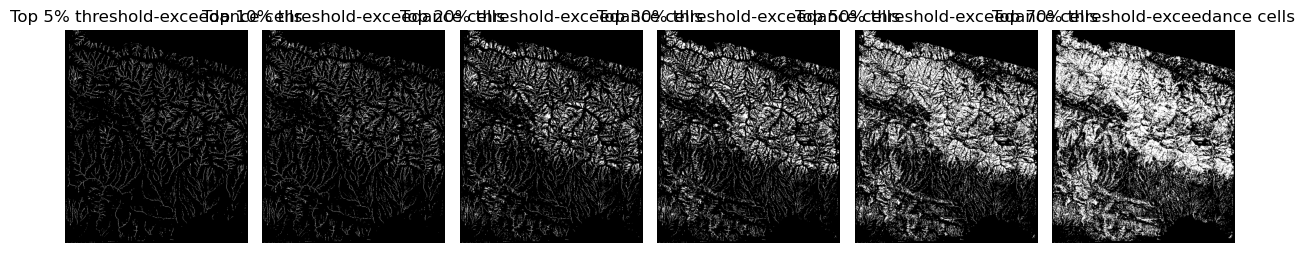

,top_percent,pci_cutoff,source_pixels,source_area_m2,source_area_km2,raster
0,5,1.000000,25828,2582800.0,2.5828,/mnt/c/Users/amehedi/Downloads/source_area_wor...
1,10,0.988667,35944,3594400.0,3.5944,/mnt/c/Users/amehedi/Downloads/source_area_wor...
2,20,0.834000,66013,6601300.0,6.6013,/mnt/c/Users/amehedi/Downloads/source_area_wor...
3,30,0.646000,95160,9516000.0,9.5160,/mnt/c/Users/amehedi/Downloads/source_area_wor...
4,50,0.260667,150987,15098700.0,15.0987,/mnt/c/Users/amehedi/Downloads/source_area_wor...
5,70,0.028000,204635,20463500.0,20.4635,/mnt/c/Users/amehedi/Downloads/source_area_wor...


In [7]:
source_maps = {}
source_rows = []

for top_percent in TOP_PERCENT_VALUES:
    cutoff = np.nanpercentile(pci[valid], 100 - top_percent)
    source = (pci >= cutoff) & erosion & valid
    source = source.astype("uint8")

    name = f"top{top_percent}_pci_dod_source_binary"
    path = OUT / f"{name}.tif"

    out_profile = profile.copy()
    out_profile.update(dtype="uint8", count=1, nodata=0, compress="deflate")
    with rasterio.open(path, "w", **out_profile) as dst:
        dst.write(source, 1)

    source_maps[top_percent] = source
    source_rows.append({
        "top_percent": top_percent,
        "pci_cutoff": cutoff,
        "source_pixels": int(source.sum()),
        "source_area_m2": float(source.sum() * cell_area_m2),
        "source_area_km2": float(source.sum() * cell_area_m2 / 1_000_000),
        "raster": str(path),
    })

source_summary = pd.DataFrame(source_rows)
source_summary.to_csv(OUT / "source_cell_summary.csv", index=False)

fig, axes = plt.subplots(1, len(TOP_PERCENT_VALUES), figsize=(12, 5))
if len(TOP_PERCENT_VALUES) == 1:
    axes = [axes]

for ax, top_percent in zip(axes, TOP_PERCENT_VALUES):
    ax.imshow(source_maps[top_percent], cmap="gray")
    ax.set_title(f"Top {top_percent}% threshold-exceedance cells")
    ax.axis("off")

plt.tight_layout()
plt.show()

source_summary

## 7. Source Candidate Polygons

Convert source cells into GeoPackage polygons for GIS and later MWR-style use.

In [8]:
def binary_to_polygons(binary, profile, out_path):
    geoms = []

    for geom, value in shapes(
        binary.astype("uint8"),
        mask=binary == 1,
        transform=profile["transform"],
    ):
        if value == 1:
            geoms.append(shape(geom))

    gdf = gpd.GeoDataFrame(
        {"source_id": range(1, len(geoms) + 1)},
        geometry=geoms,
        crs=profile["crs"],
    )

    if len(gdf) > 0:
        gdf["mass__wasting_id"] = gdf["source_id"]
        gdf["area_m2"] = gdf.geometry.area
        gdf["area_km2"] = gdf["area_m2"] / 1_000_000

    out_path = Path(out_path)
    if out_path.exists():
        out_path.unlink()
    gdf.to_file(out_path, driver="GPKG")
    return gdf


polygon_rows = []

for top_percent, source in source_maps.items():
    polygon_path = OUT / f"top{top_percent}_pci_dod_source_polygons.gpkg"
    gdf = binary_to_polygons(source, profile, polygon_path)

    polygon_rows.append({
        "top_percent": top_percent,
        "n_polygons": len(gdf),
        "polygon_area_km2": float(gdf["area_km2"].sum()) if len(gdf) else 0.0,
        "polygon_file": str(polygon_path),
    })

polygon_summary = pd.DataFrame(polygon_rows)
polygon_summary.to_csv(OUT / "source_polygon_summary.csv", index=False)

polygon_summary

,top_percent,n_polygons,polygon_area_km2,polygon_file
0,5,10537,2.5828,/mnt/c/Users/amehedi/Downloads/source_area_wor...
1,10,12567,3.5944,/mnt/c/Users/amehedi/Downloads/source_area_wor...
2,20,14607,6.6013,/mnt/c/Users/amehedi/Downloads/source_area_wor...
3,30,15056,9.5160,/mnt/c/Users/amehedi/Downloads/source_area_wor...
4,50,15236,15.0987,/mnt/c/Users/amehedi/Downloads/source_area_wor...
5,70,13483,20.4635,/mnt/c/Users/amehedi/Downloads/source_area_wor...


## 8. Final Outputs

Main products from this notebook:

- `c_samples.csv`
- `pci_from_c_cdf.tif`
- `erosion_mask_dod_lt_minus_0p277.tif`
- `top10_pci_dod_source_binary.tif`
- `top5_pci_dod_source_binary.tif`
- `top10_pci_dod_source_polygons.gpkg`
- `top5_pci_dod_source_polygons.gpkg`
- summary CSV files

Lithology/Dunne analysis should be run as a separate interpretation/validation workflow using these source products.

In [8]:
print("Output folder:", OUT)
print("Files:")
for path in sorted(OUT.glob("*")):
    print("-", path.name)

Output folder: /mnt/c/Users/amehedi/Downloads/source_area_workflow
Files:
- C10_DOD_exclude_channel.tif
- C10_DOD_exclude_channel.tif.aux.xml
- C15_DOD_exclude_channel.tif
- C15_DOD_exclude_channel.tif.aux.xml
- C20_DOD_exclude_channel.tif
- C20_DOD_exclude_channel.tif.aux.xml
- C5_DOD_exclude_channel.tif
- C5_DOD_exclude_channel.tif.aux.xml
- G_gt_100_no_DoD_filter.tif
- G_gt_100_no_DoD_filter.tif.aux.xml
- G_gt_120_no_DoD_filter.tif
- G_gt_120_no_DoD_filter.tif.aux.xml
- G_gt_5_no_DoD_filter.tif
- G_gt_5_no_DoD_filter.tif.aux.xml
- c_samples.csv
- candidate_G_gt_C_10.tif
- candidate_G_gt_C_10.tif.aux.xml
- candidate_G_gt_C_100.tif
- candidate_G_gt_C_100.tif.aux.xml
- candidate_G_gt_C_100_dod_lt_minus_0p277.tif
- candidate_G_gt_C_100_dod_lt_minus_0p277.tif.aux.xml
- candidate_G_gt_C_10_dod_lt_minus_0p277.tif
- candidate_G_gt_C_110_dod_lt_minus_0p277.tif
- candidate_G_gt_C_110_dod_lt_minus_0p277.tif.aux.xml
- candidate_G_gt_C_120_dod_lt_minus_0p277.tif
- candidate_G_gt_C_120_dod_lt_min

In [21]:
from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster

G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))

pci_path = "/mnt/c/Users/amehedi/Downloads/source_area_workflow/pci_from_c_cdf.tif"
pci, _ = read_raster(pci_path)

valid = np.isfinite(G) & np.isfinite(pci)

top_percents = [5, 10, 20, 30, 40, 50]

rows = []

for top in top_percents:
    pci_cutoff = np.nanpercentile(pci[valid], 100 - top)

    selected = valid & (pci >= pci_cutoff)

    rows.append({
        "top_percent": top,
        "pci_cutoff": pci_cutoff,
        "G_min_selected": np.nanmin(G[selected]),
        "G_mean_selected": np.nanmean(G[selected]),
        "G_median_selected": np.nanmedian(G[selected]),
        "G_max_selected": np.nanmax(G[selected]),
        "n_cells": int(selected.sum()),
    })

cutoff_table = pd.DataFrame(rows)
cutoff_table

,top_percent,pci_cutoff,G_min_selected,G_mean_selected,G_median_selected,G_max_selected,n_cells
0,5,1.000000,161.392441,3512.945091,529.509766,1108000.875,40065
1,10,0.988667,91.360199,2451.941190,275.914032,1108000.875,58291
2,20,0.834000,41.675522,1259.716575,91.743206,1108000.875,116192
3,30,0.646000,26.876587,851.562050,56.468653,1108000.875,174156
4,40,0.436000,18.469082,644.945937,41.760328,1108000.875,231954
5,50,0.260667,12.728029,518.609025,32.986435,1108000.875,290187


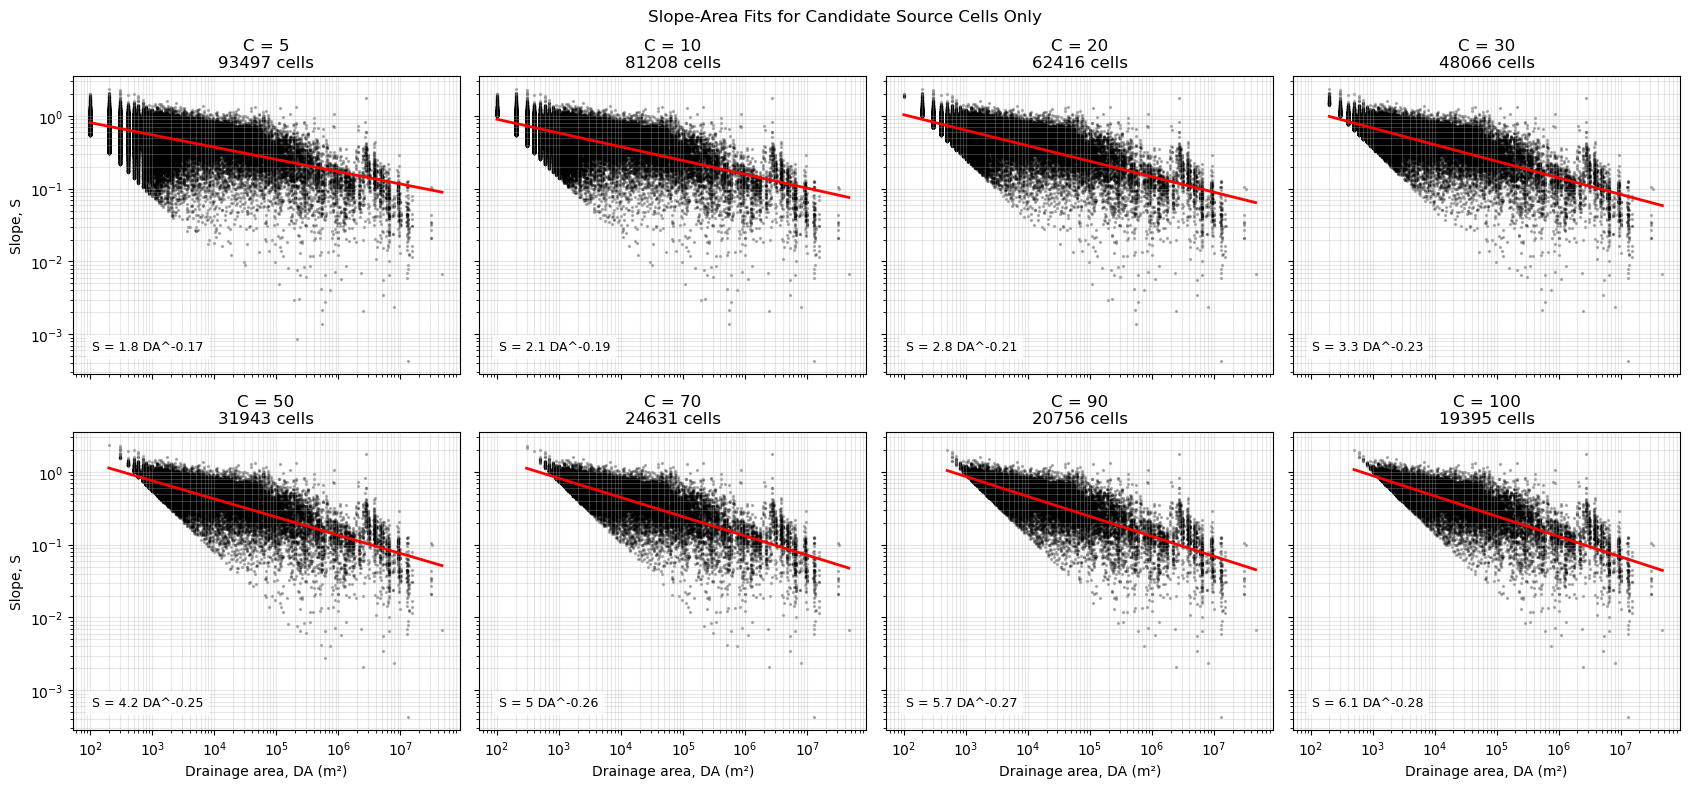

In [10]:
import numpy as np
import matplotlib.pyplot as plt

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster

S, profile = read_raster(output_path(cfg, "slope", "slope.tif"))
a, _ = read_raster(output_path(cfg, "specific_catchment_area", "specific_catchment_area.tif"))
G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
dem_diff, _ = read_raster(cfg["paths"]["dem_diff"])

cell_size = abs(profile["transform"].a)
DA = a * cell_size

C_values = [5, 10, 20, 30, 50, 70, 90, 100]

erosion = dem_diff < -0.277

valid = (
    np.isfinite(S) &
    np.isfinite(DA) &
    np.isfinite(G) &
    np.isfinite(dem_diff) &
    (S > 0) &
    (DA > 0)
)

fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, C in zip(axes, C_values):

    candidate = valid & erosion & (G >= C)

    x = DA[candidate]
    y = S[candidate]

    ax.scatter(x, y, s=2, alpha=0.25, color="black")

    if len(x) > 2:
        log_x = np.log10(x)
        log_y = np.log10(y)

        slope_fit, intercept_fit = np.polyfit(log_x, log_y, 1)

        x_line = np.logspace(np.log10(x.min()), np.log10(x.max()), 100)
        y_line = 10**intercept_fit * x_line**slope_fit

        ax.plot(x_line, y_line, color="red", linewidth=2)

        equation = f"S = {10**intercept_fit:.2g} DA^{slope_fit:.2f}"
    else:
        equation = "not enough cells"

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"C = {C}\n{len(x)} cells")
    ax.text(
        0.05, 0.08,
        equation,
        transform=ax.transAxes,
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )
    ax.grid(True, which="both", alpha=0.3)

for ax in axes[4:]:
    ax.set_xlabel("Drainage area, DA (m²)")

for ax in axes[::4]:
    ax.set_ylabel("Slope, S")

plt.suptitle("Slope-Area Fits for Candidate Source Cells Only")
plt.tight_layout()
plt.show()

C values: [ 6.17451698 12.51681443 21.14836569 34.0351065  62.82009691]


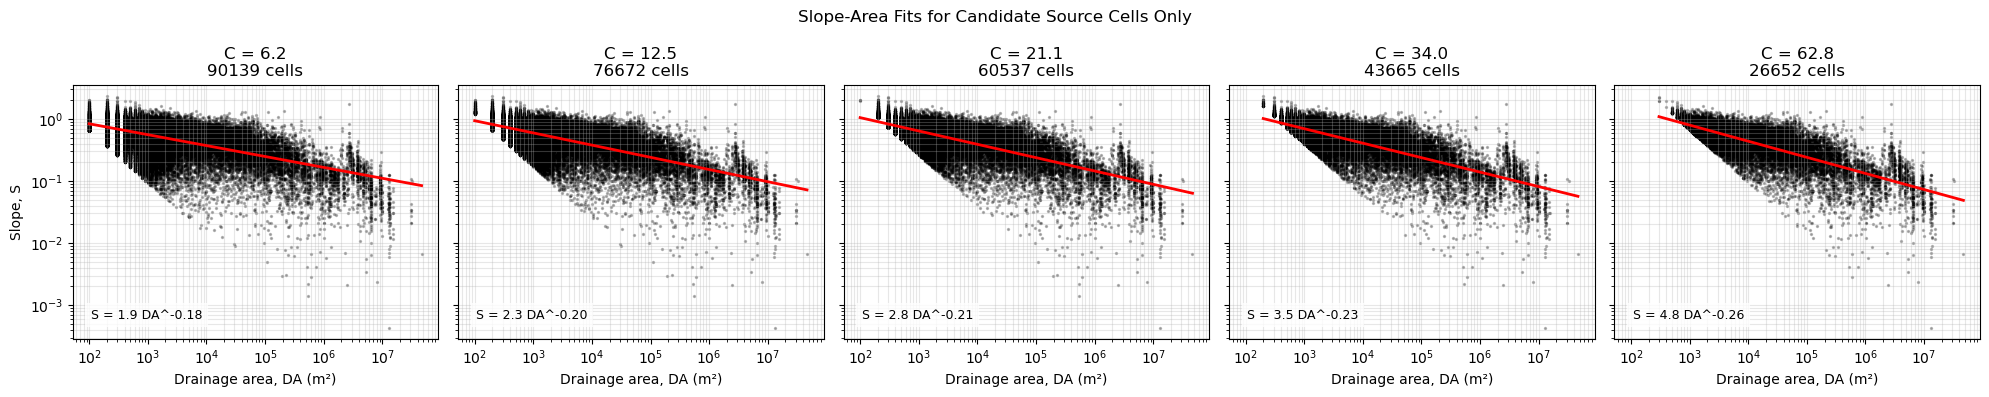

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster

# load rasters
S, profile = read_raster(output_path(cfg, "slope", "slope.tif"))
a, _ = read_raster(output_path(cfg, "specific_catchment_area", "specific_catchment_area.tif"))
G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
dem_diff, _ = read_raster(cfg["paths"]["dem_diff"])

cell_size = abs(profile["transform"].a)
DA = a * cell_size

# keep observed erosion cells only
erosion = dem_diff < -0.277

# choose 5 C values from sampled C distribution
c_table = pd.read_csv("/mnt/c/Users/amehedi/Downloads/source_area_workflow/c_samples.csv")
C_values = np.nanpercentile(c_table["C"], [5, 25, 50, 75, 95])

print("C values:", C_values)

valid = (
    np.isfinite(S) &
    np.isfinite(DA) &
    np.isfinite(G) &
    np.isfinite(dem_diff) &
    (S > 0) &
    (DA > 0)
)

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)

for ax, C in zip(axes, C_values):

    candidate = valid & erosion & (G >= C)

    x = DA[candidate]
    y = S[candidate]

    ax.scatter(x, y, s=2, alpha=0.25, color="black")

    if len(x) > 2:
        log_x = np.log10(x)
        log_y = np.log10(y)

        slope_fit, intercept_fit = np.polyfit(log_x, log_y, 1)

        x_line = np.logspace(np.log10(x.min()), np.log10(x.max()), 100)
        y_line = 10**intercept_fit * x_line**slope_fit

        ax.plot(x_line, y_line, color="red", linewidth=2)

        equation = f"S = {10**intercept_fit:.2g} DA^{slope_fit:.2f}"
    else:
        equation = "not enough cells"

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"C = {C:.1f}\n{len(x)} cells")
    ax.text(
        0.05, 0.08,
        equation,
        transform=ax.transAxes,
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )
    ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel("Slope, S")

for ax in axes:
    ax.set_xlabel("Drainage area, DA (m²)")

plt.suptitle("Slope-Area Fits for Candidate Source Cells Only")
plt.tight_layout()
plt.show()

In [12]:
import geopandas as gpd

nhd_path = "/mnt/c/Users/amehedi/Downloads/nhdplus_hr_flowlines.gpkg"
nhd = gpd.read_file(nhd_path, layer="flowlines")

nhd.head()

,OBJECTID,permanent_identifier,fdate,resolution,gnis_id,gnis_name,lengthkm,reachcode,flowdir,wbarea_permanent_identifier,...,qlossma,qgadjma,qgnavma,gageadjma,avgqadjma,gageidma,gageqma,Shape_Length,clipped_length_km,geometry
0,13662894,27716783,1508716800000,2,00254322,Sycamore Creek,2.941701,18060013000508,1,None,...,0,0,0,0,0,0,0,3561.473992,1.806504,"LINESTRING (-119.6764 34.4383, -119.67642 34.4..."
1,23271832,27716769,1508716800000,2,None,None,0.553321,18060013001013,1,None,...,0,0,0,0,0,0,0,668.428211,0.549802,"LINESTRING (-119.66051 34.42998, -119.66056 34..."
2,16141161,27716787,1329747450000,2,00246127,Montecito Creek,3.653000,18060013000519,1,None,...,0,0,0,0,0,0,0,4424.928629,2.317884,"LINESTRING (-119.65039 34.44297, -119.65024 34..."
3,18303541,27716767,1329747414000,2,None,None,1.638000,18060013000175,1,None,...,0,0,0,0,0,0,0,1980.556877,1.629753,"LINESTRING (-119.66749 34.43794, -119.66758 34..."
4,19141248,{B6C32CAC-979A-4361-B362-07B2288676F6},1508716800000,2,None,None,0.209478,18060013000512,1,None,...,0,0,0,0,0,0,0,254.339171,0.209577,"LINESTRING (-119.66903 34.44296, -119.66948 34..."


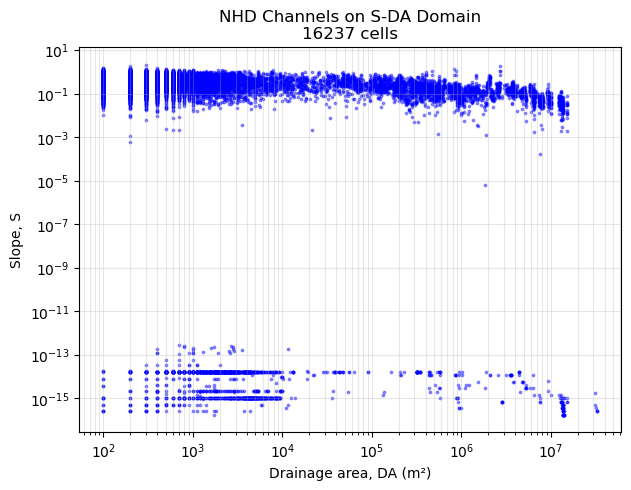

In [12]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from rasterio.features import geometry_mask

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster

# paths
nhd_path = "/mnt/c/Users/amehedi/Downloads/nhdplus_hr_flowlines.gpkg"

# load rasters
S, profile = read_raster(output_path(cfg, "slope", "slope.tif"))
a, _ = read_raster(output_path(cfg, "specific_catchment_area", "specific_catchment_area.tif"))

cell_size = abs(profile["transform"].a)
DA = a * cell_size

# load NHD lines and match raster CRS
nhd = gpd.read_file(nhd_path, layer="flowlines")
nhd = nhd.to_crs(profile["crs"])

# buffer lines by one cell width, then make raster mask
nhd_buffer = nhd.copy()
nhd_buffer["geometry"] = nhd_buffer.geometry.buffer(cell_size)

nhd_mask = geometry_mask(
    nhd_buffer.geometry,
    out_shape=S.shape,
    transform=profile["transform"],
    invert=True
)

# extract slope and drainage area for NHD cells
valid = np.isfinite(S) & np.isfinite(DA) & (S > 0) & (DA > 0)
nhd_cells = valid & nhd_mask

x = DA[nhd_cells]
y = S[nhd_cells]

# plot S-DA for NHD channel cells
plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=3, alpha=0.4, color="blue")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Drainage area, DA (m²)")
plt.ylabel("Slope, S")
plt.title(f"NHD Channels on S-DA Domain\n{len(x)} cells")
plt.grid(True, which="both", alpha=0.3)
plt.show()

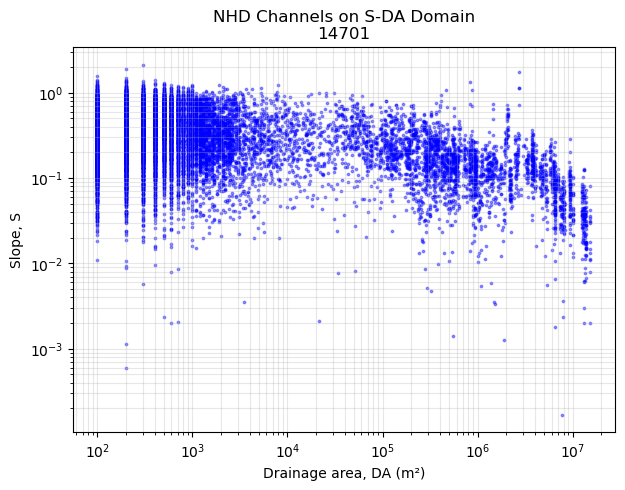

In [17]:
nhd_cells_clean = nhd_cells & (S > 1e-4)

x = DA[nhd_cells_clean]
y = S[nhd_cells_clean]

plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=3, alpha=0.4, color="blue")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Drainage area, DA (m²)")
plt.ylabel("Slope, S")
plt.title(f"NHD Channels on S-DA Domain\n{len(x)}")
plt.grid(True, which="both", alpha=0.3)
plt.show()

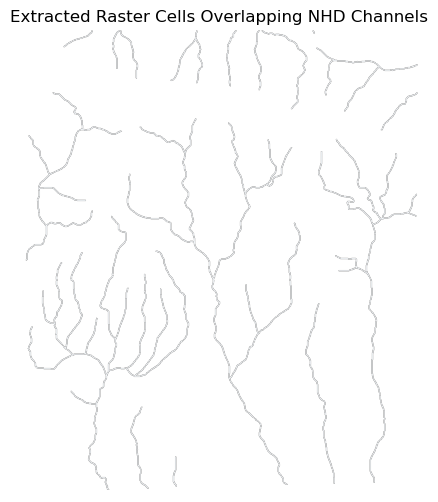

In [ ]:
plt.figure(figsize=(8, 6))

# background = slope or just empty mask
# plt.imshow(S, cmap="terrain", alpha=0.7)

# overlay NHD extracted raster cells
plt.imshow(np.where(nhd_cells, 1, np.nan), cmap="Blues", alpha=0.9)

plt.title("Extracted Raster Cells Overlapping NHD Channels")
plt.axis("off")
plt.show()

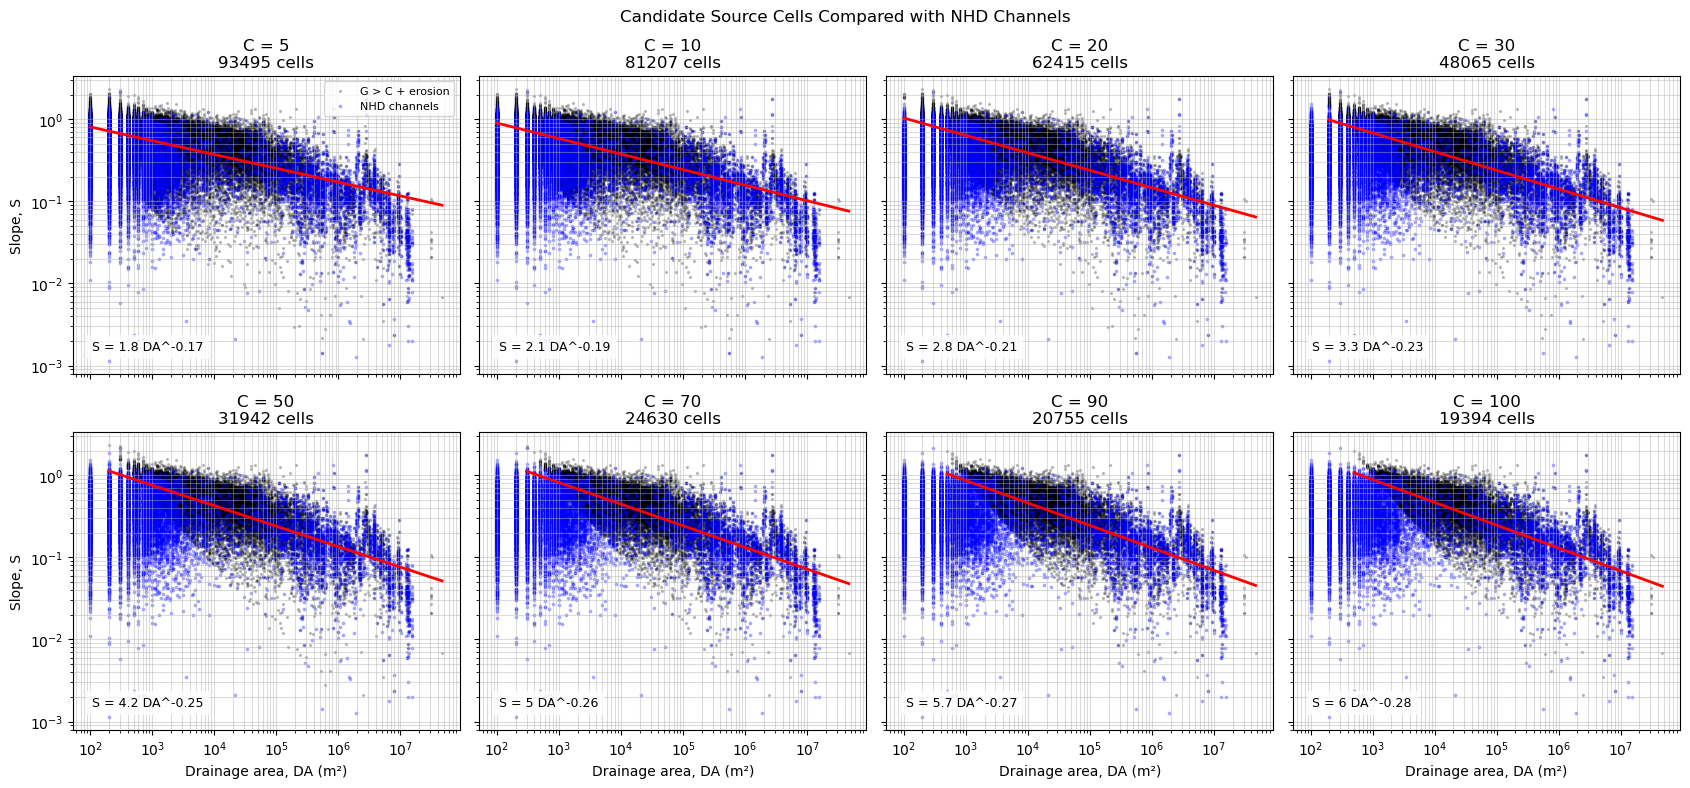

In [ ]:
from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster

# load rasters
S, profile = read_raster(output_path(cfg, "slope", "slope.tif"))
a, _ = read_raster(output_path(cfg, "specific_catchment_area", "specific_catchment_area.tif"))
G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
dem_diff, _ = read_raster(cfg["paths"]["dem_diff"])

cell_size = abs(profile["transform"].a)
DA = a * cell_size

C_values = [5, 10, 20, 30, 50, 70, 90, 100]

erosion = dem_diff < -0.277

valid = (
    np.isfinite(S) &
    np.isfinite(DA) &
    np.isfinite(G) &
    np.isfinite(dem_diff) &
    (S > 1e-3) &
    (DA > 0)
)

# NHD cells, cleaned
nhd_cells_clean = nhd_cells & valid

x_nhd = DA[nhd_cells_clean]
y_nhd = S[nhd_cells_clean]

fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, C in zip(axes, C_values):

    # candidate source cells for this C
    candidate = valid & erosion & (G >= C)

    x = DA[candidate]
    y = S[candidate]

    # black = our extracted candidate cells
    ax.scatter(x, y, s=2, alpha=0.20, color="black", label="G > C + erosion")

    # blue = mapped NHD channel cells
    ax.scatter(x_nhd, y_nhd, s=3, alpha=0.25, color="blue", label="NHD channels")

    # fit candidate cells only
    if len(x) > 2:
        log_x = np.log10(x)
        log_y = np.log10(y)

        slope_fit, intercept_fit = np.polyfit(log_x, log_y, 1)

        x_line = np.logspace(np.log10(x.min()), np.log10(x.max()), 100)
        y_line = 10**intercept_fit * x_line**slope_fit

        ax.plot(x_line, y_line, color="red", linewidth=2)

        equation = f"S = {10**intercept_fit:.2g} DA^{slope_fit:.2f}"
    else:
        equation = "not enough cells"

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"C = {C}\n{len(x)} cells")
    ax.text(
        0.05, 0.08,
        equation,
        transform=ax.transAxes,
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )
    ax.grid(True, which="both", alpha=0.45)

for ax in axes[4:]:
    ax.set_xlabel("Drainage area, DA (m²)")

for ax in axes[::4]:
    ax.set_ylabel("Slope, S")

axes[0].legend(loc="upper right", fontsize=8)

plt.suptitle("Candidate Source Cells Compared with NHD Channels")
plt.tight_layout()
plt.show()

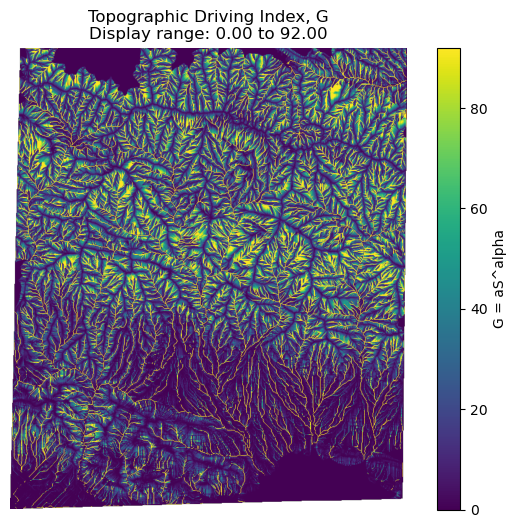

saved: /mnt/c/Users/amehedi/Downloads/G_topographic_driving_index.tif
G min/max: 0.0 1108000.875
G 99th percentile: 3521.8755346679714


In [ ]:

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster, write_raster

G, profile = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))

# choose display range
vmin = 0
vmax = np.nanpercentile(G, 90)   # change this if needed

plt.figure(figsize=(8, 6))
plt.imshow(G, cmap="viridis", vmin=vmin, vmax=vmax)
plt.colorbar(label="G = aS^alpha")
plt.title(f"Topographic Driving Index, G\nDisplay range: {vmin:.2f} to {vmax:.2f}")
plt.axis("off")
plt.show()

# export raster unchanged
out_path = "/mnt/c/Users/amehedi/Downloads/G_topographic_driving_index.tif"
write_raster(out_path, G, profile)

print("saved:", out_path)
print("G min/max:", np.nanmin(G), np.nanmax(G))
print("G 99th percentile:", np.nanpercentile(G, 99))

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_5.tif cells: 409745
saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_10.tif cells: 321414
saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_20.tif cells: 219658
saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_30.tif cells: 158223
saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_50.tif cells: 97564
saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_70.tif cells: 72090
saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_90.tif cells: 58953
saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_100.tif cells: 54514


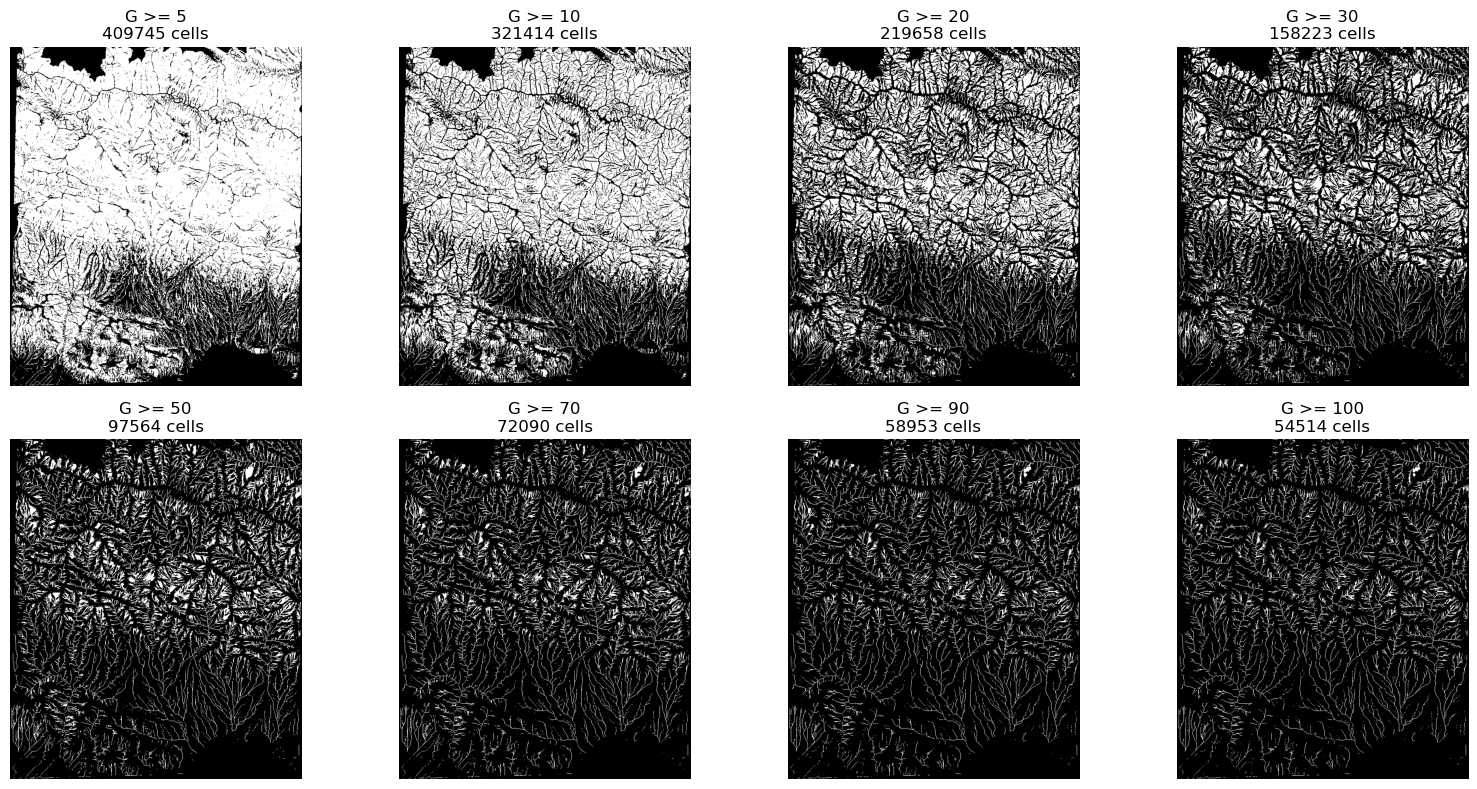

In [25]:
import numpy as np
import matplotlib.pyplot as plt

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster
from pci_source_zones.physics.source_area import write_binary_raster

# load G
G, profile = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))

# C values from S-DA plots
C_values = [5, 10, 20, 30, 50, 70, 90, 100]

OUT = "/mnt/c/Users/amehedi/Downloads/source_area_workflow"

valid = np.isfinite(G)

for C in C_values:
    candidate = valid & (G >= C)

    out_path = f"{OUT}/candidate_G_gt_C_{C}.tif"
    write_binary_raster(out_path, candidate.astype("uint8"), profile)

    print("saved:", out_path, "cells:", int(candidate.sum()))

# quick plot
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, C in zip(axes, C_values):
    candidate = valid & (G >= C)

    ax.imshow(candidate, cmap="gray")
    ax.set_title(f"G >= {C}\n{candidate.sum()} cells")
    ax.axis("off")

plt.tight_layout()
plt.show()

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_110_dod_lt_minus_0p277.tif cells: 18330
saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_120_dod_lt_minus_0p277.tif cells: 17486


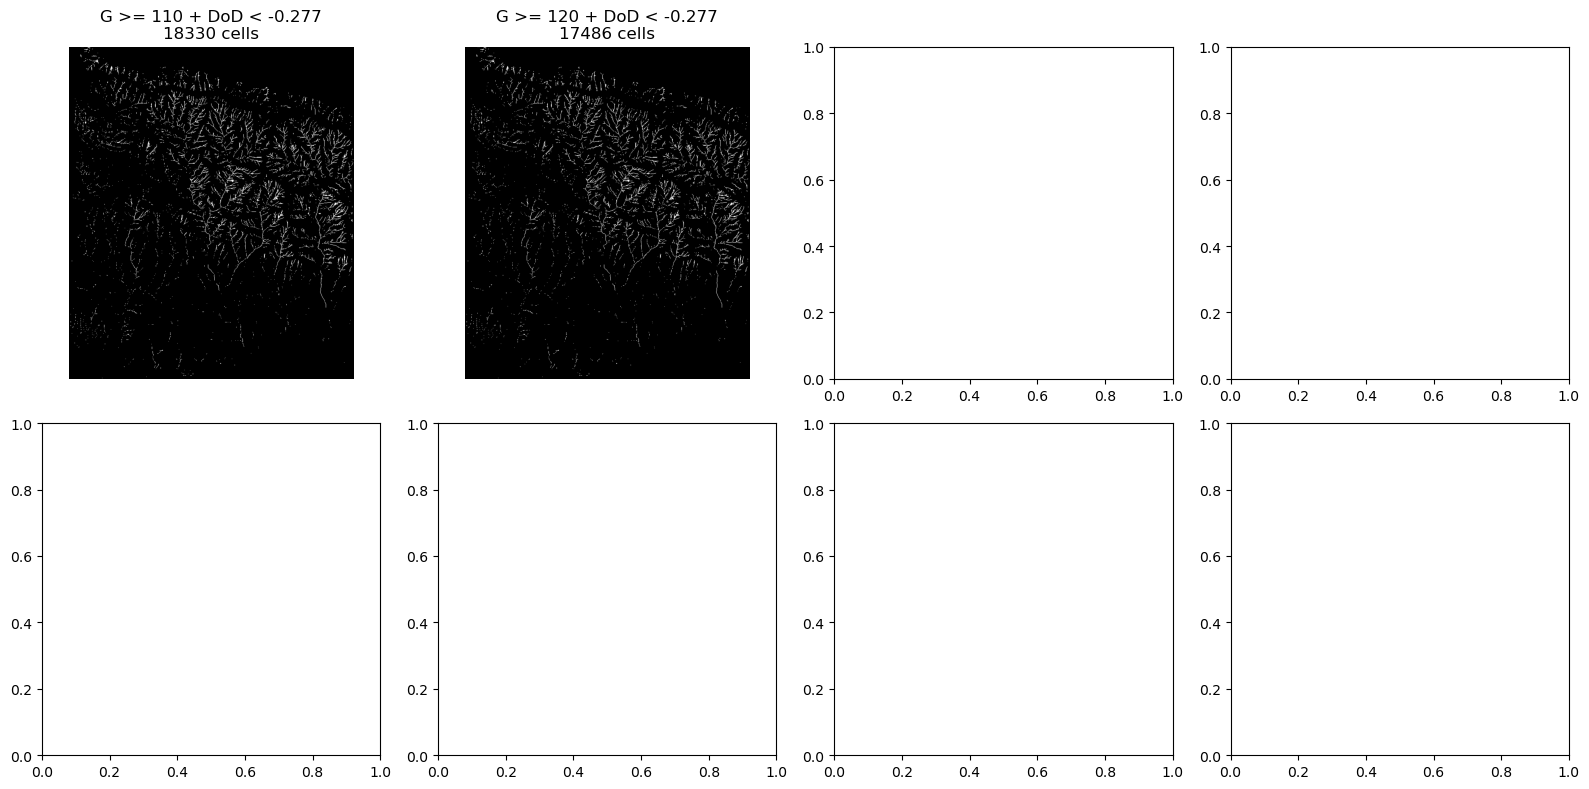

In [ ]:
from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster
from pci_source_zones.physics.source_area import write_binary_raster

# load G and dem difference
G, profile = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
dem_diff, _ = read_raster(cfg["paths"]["dem_diff"])

C_values = [110, 120]

OUT = "/mnt/c/Users/amehedi/Downloads/source_area_workflow"

valid = np.isfinite(G) & np.isfinite(dem_diff)
erosion = dem_diff < -0.277

for C in C_values:
    candidate = valid & erosion & (G >= C)

    out_path = f"{OUT}/candidate_G_gt_C_{C}_dod_lt_minus_0p277.tif"
    write_binary_raster(out_path, candidate.astype("uint8"), profile)

    print("saved:", out_path, "cells:", int(candidate.sum()))

# quick plot
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, C in zip(axes, C_values):
    candidate = valid & erosion & (G >= C)

    ax.imshow(candidate, cmap="gray")
    ax.set_title(f"G >= {C} + DoD < -0.277\n{candidate.sum()} cells")
    ax.axis("off")

plt.tight_layout()
plt.show()

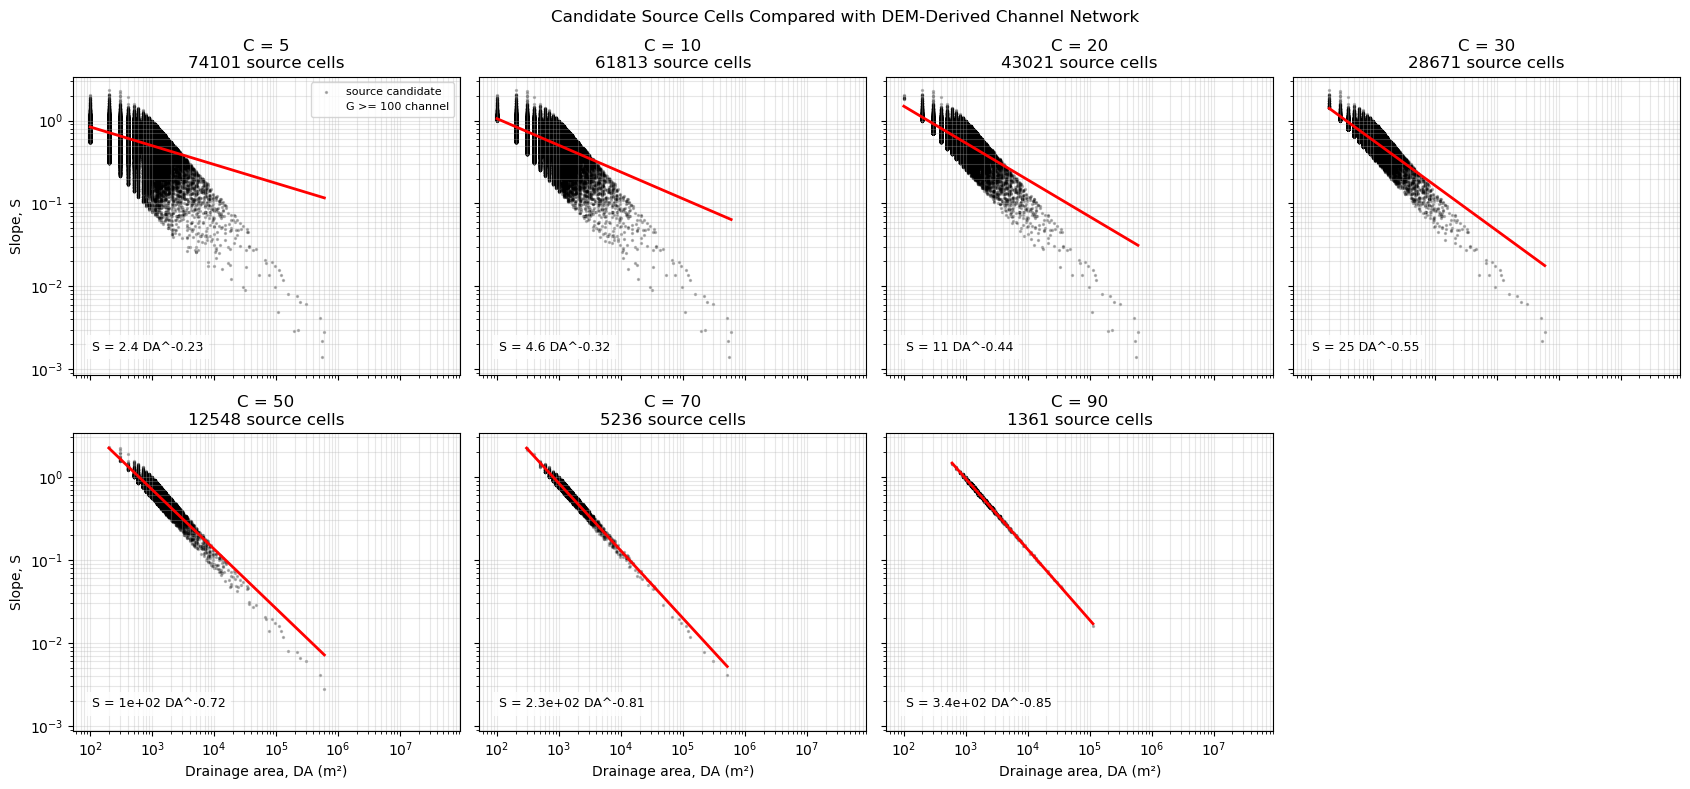

In [ ]:
from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster

# load rasters
S, profile = read_raster(output_path(cfg, "slope", "slope.tif"))
a, _ = read_raster(output_path(cfg, "specific_catchment_area", "specific_catchment_area.tif"))
G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
dem_diff, _ = read_raster(cfg["paths"]["dem_diff"])

cell_size = abs(profile["transform"].a)
DA = a * cell_size

# candidate C values, excluding 100 because 100 is channel network
C_values = [5, 10, 20, 30, 50, 70, 90]

channel_C = 100

valid = (
    np.isfinite(S) &
    np.isfinite(DA) &
    np.isfinite(G) &
    np.isfinite(dem_diff) &
    (S > 1e-3) &
    (DA > 0)
)

# erosion = dem_diff < -0.277

# DEM-derived channel network
channel_cells = valid & (G >= channel_C)

x_channel = DA[channel_cells]
y_channel = S[channel_cells]

fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, C in zip(axes, C_values):

    # source candidates exclude the main channel network
    candidate = valid & erosion & (G >= C) & (G < channel_C)

    x = DA[candidate]
    y = S[candidate]

    # black = source candidates
    ax.scatter(x, y, s=2, alpha=0.25, color="black", label="source candidate")

    # blue = DEM-derived channel network
    ax.scatter(x_channel, y_channel, s=3, alpha=0.0, color="blue", label="G >= 100 channel")

    # fit source candidates only
    if len(x) > 2:
        log_x = np.log10(x)
        log_y = np.log10(y)

        slope_fit, intercept_fit = np.polyfit(log_x, log_y, 1)

        x_line = np.logspace(np.log10(x.min()), np.log10(x.max()), 100)
        y_line = 10**intercept_fit * x_line**slope_fit

        ax.plot(x_line, y_line, color="red", linewidth=2)

        equation = f"S = {10**intercept_fit:.2g} DA^{slope_fit:.2f}"
    else:
        equation = "not enough cells"

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"C = {C}\n{len(x)} source cells")
    ax.text(
        0.05, 0.08,
        equation,
        transform=ax.transAxes,
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )
    ax.grid(True, which="both", alpha=0.3)

# hide the unused 8th panel
axes[-1].axis("off")

for ax in axes[4:7]:
    ax.set_xlabel("Drainage area, DA (m²)")

for ax in [axes[0], axes[4]]:
    ax.set_ylabel("Slope, S")

axes[0].legend(loc="upper right", fontsize=8)

plt.suptitle("Candidate Source Cells Compared with DEM-Derived Channel Network")
plt.tight_layout()
plt.show()

In [2]:
from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt

OUT = Path("/mnt/c/Users/amehedi/Downloads/source_area_workflow")

C_values = [110, 120]

paths = [
    OUT / f"candidate_G_gt_C_{C}_dod_lt_minus_0p277.tif"
    for C in C_values
]

# read and count overlaps
arrays = []

for path in paths:
    with rasterio.open(path) as src:
        arr = src.read(1)
        profile = src.profile.copy()
    arrays.append(arr == 1)

overlap_count = np.sum(arrays, axis=0).astype("uint8")

# save class raster
out_path = OUT / "candidate_overlap_classes.tif"

profile.update(
    dtype="uint8",
    count=1,
    nodata=0,
    compress="deflate"
)

with rasterio.open(out_path, "w", **profile) as dst:
    dst.write(overlap_count, 1)

print("saved:", out_path)
print("max class:", overlap_count.max())

# plot
plt.figure(figsize=(8, 6))
plt.imshow(overlap_count, cmap="viridis", vmin=0, vmax=len(C_values))
plt.colorbar(label="Number of overlapping candidate layers")
plt.title("Candidate Source Overlap Classes")
plt.axis("off")
plt.show()

RasterioIOError: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G_gt_C_110_dod_lt_minus_0p277.tif: No such file or directory

In [24]:
import numpy as np

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster
from pci_source_zones.physics.source_area import write_binary_raster

# load G
G, profile = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))

valid = np.isfinite(G)

for C in [5]:
    channel = valid & (G > C)

    out_path = f"/mnt/c/Users/amehedi/Downloads/source_area_workflow/G_gt_{C}_no_DoD_filter.tif"

    write_binary_raster(out_path, channel.astype("uint8"), profile)

    print("saved:", out_path)
    print(f"G > {C} cells:", int(channel.sum()))

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/G_gt_5_no_DoD_filter.tif
G > 5 cells: 409745


In [46]:
# ax = groups_dissolved.plot(
#     column="population",
#     cmap="Set2",
#     edgecolor="black",
#     figsize=(8, 6),
#     legend=True
# )

# for _, row in groups_dissolved.iterrows():
#     p = row.geometry.representative_point()
#     ax.text(p.x, p.y, row["population"], fontsize=14, ha="center", va="center")

# plt.title("Aggregated Dunne Populations")
# plt.axis("off")
# plt.show()

In [14]:
from pathlib import Path

import numpy as np
import rasterio

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster

# --------------------
# 1. Inputs
# --------------------
dem_diff_path = "/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated.tif"
out_path = Path("/mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G10_lt_G120_dod_lt_minus_0p05.tif")

C_source = 10
C_channel = 120
dod_threshold = -0.05

nodata = 255

# --------------------
# 2. Load rasters
# --------------------
S, profile = read_raster(output_path(cfg, "slope", "slope.tif"))
a, _ = read_raster(output_path(cfg, "specific_catchment_area", "specific_catchment_area.tif"))
G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
dem_diff, _ = read_raster(dem_diff_path)

cell_size = abs(float(profile["transform"].a))
DA = a * cell_size

# --------------------
# 3. Make valid mask
# --------------------
valid = (
    np.isfinite(S) &
    np.isfinite(a) &
    np.isfinite(DA) &
    np.isfinite(G) &
    np.isfinite(dem_diff) &
    (S > 0) &
    (DA > 0)
)

# --------------------
# 4. Make binary source target
# --------------------
source = (
    valid &
    (G >= C_source) &
    (G < C_channel) &
    (dem_diff < dod_threshold)
)

target = np.full(G.shape, nodata, dtype="uint8")
target[valid] = 0
target[source] = 1

# --------------------
# 5. Export raster
# --------------------
out_path.parent.mkdir(parents=True, exist_ok=True)

meta = profile.copy()
meta.update(
    driver="GTiff",
    count=1,
    dtype="uint8",
    nodata=nodata,
    compress="deflate",
)

if not meta.get("tiled", False):
    meta.pop("blockxsize", None)
    meta.pop("blockysize", None)

with rasterio.open(out_path, "w", **meta) as dst:
    dst.write(target, 1)

print("saved:", out_path)
print("0 valid non-source:", int((target == 0).sum()))
print("1 candidate source:", int((target == 1).sum()))
print("255 nodata:", int((target == nodata).sum()))

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/candidate_G10_lt_G120_dod_lt_minus_0p05.tif
0 valid non-source: 425326
1 candidate source: 103156
255 nodata: 69378


In [12]:
out_path = "/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated_lt_minus_0p05_no_channels_binary.tif"

C_CHANNEL = 120

dem_diff, profile = read_raster(dem_diff_path)
G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))

non_channel = np.isfinite(G) & (G < C_CHANNEL)

binary = np.zeros(dem_diff.shape, dtype="uint8")
binary[np.isfinite(dem_diff) & (dem_diff < -0.05) & non_channel] = 1

meta = profile.copy()
meta.update(
    driver="GTiff",
    count=1,
    dtype="uint8",
    nodata=255,
    compress="deflate",
)

if not meta.get("tiled", False):
    meta.pop("blockxsize", None)
    meta.pop("blockysize", None)

with rasterio.open(out_path, "w", **meta) as dst:
    dst.write(binary, 1)

print("saved:", out_path)
print("source pixels, channels omitted:", int(binary.sum()))

saved: /mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated_lt_minus_0p05_no_channels_binary.tif
source pixels, channels omitted: 170852


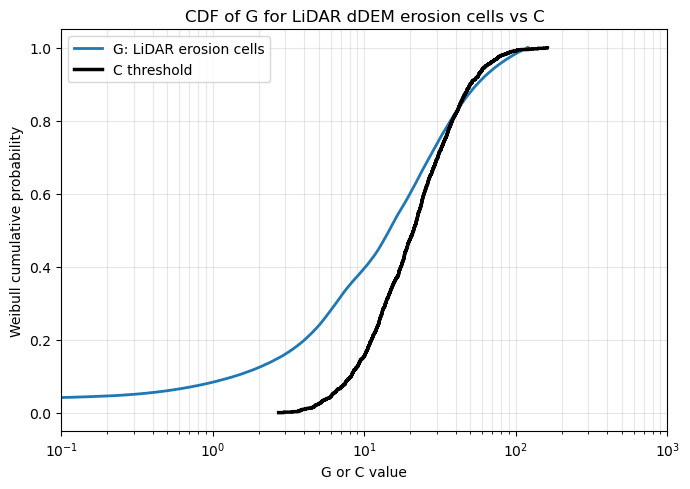

G cells: 170849
G min: 2.4733111837690273e-18
G median: 14.60469913482666
G max: 119.99481964111328
C samples: 1500
C min: 2.715374629992217
C median: 21.148365686516737
C max: 161.39092986695303


In [9]:
binary_path = "/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated_lt_minus_0p05_no_channels_binary.tif"
c_path = "/mnt/c/Users/amehedi/Downloads/source_area_workflow/c_samples.csv"

binary, _ = read_raster(binary_path)
G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))

mask = (binary == 1) & np.isfinite(G) & (G > 0)
G_lidar_diff = G[mask]

c_table = pd.read_csv(c_path)
C_values = c_table["C"].dropna().values
C_values = C_values[np.isfinite(C_values) & (C_values > 0)]

def weibull_cdf(values):
    x = np.sort(values[np.isfinite(values)])
    y = np.arange(1, len(x) + 1) / (len(x) + 1)
    return x, y

x_g, y_g = weibull_cdf(G_lidar_diff)
x_c, y_c = weibull_cdf(C_values)

plt.figure(figsize=(7, 5))
plt.step(x_g, y_g, where="post", linewidth=2, label="G: LiDAR erosion cells")
plt.step(x_c, y_c, where="post", linewidth=2.5, color="black", label="C threshold")

plt.xscale("log")
plt.xlabel("G or C value")
plt.ylabel("Weibull cumulative probability")
plt.xlim(0.1, 1000)
plt.title("CDF of G for LiDAR dDEM erosion cells vs C")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("G cells:", len(G_lidar_diff))
print("G min:", np.nanmin(G_lidar_diff))
print("G median:", np.nanmedian(G_lidar_diff))
print("G max:", np.nanmax(G_lidar_diff))

print("C samples:", len(C_values))
print("C min:", np.nanmin(C_values))
print("C median:", np.nanmedian(C_values))
print("C max:", np.nanmax(C_values))

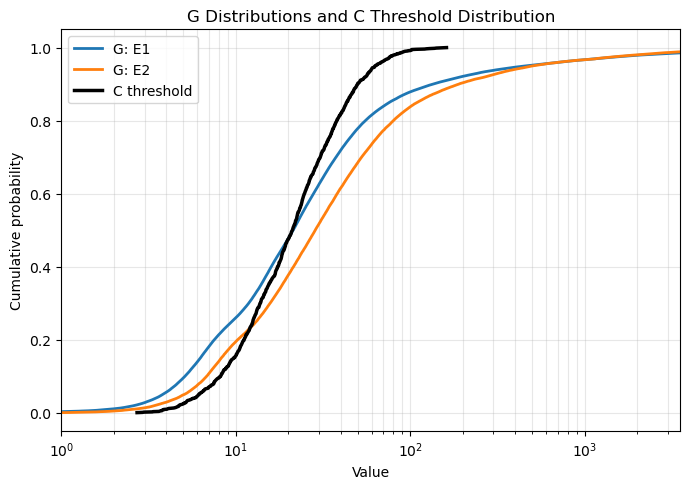

saved: /mnt/c/Users/amehedi/Downloads/dunne_E1_E2_populations.gpkg


In [47]:
from rasterio.features import geometry_mask
from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster

poly_path = "/mnt/c/Users/amehedi/Downloads/dunne_lithology_polygons_unlabeled.gpkg"
c_table_path = "/mnt/c/Users/amehedi/Downloads/source_area_workflow/c_samples.csv"
out_path = "/mnt/c/Users/amehedi/Downloads/dunne_E1_E2_populations.gpkg"

# polygons -> E1/E2
polys = gpd.read_file(poly_path)

polys["population"] = "other"
polys.loc[polys["poly_id"].isin([3, 4, 6]), "population"] = "E1"
polys.loc[polys["poly_id"].isin([1]), "population"] = "E2"

groups = polys[polys["population"].isin(["E1", "E2"])].copy()
groups_dissolved = groups.dissolve(by="population", as_index=False)

# load G and match CRS
G, profile = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))

if groups_dissolved.crs != profile["crs"]:
    groups_dissolved = groups_dissolved.to_crs(profile["crs"])

groups_dissolved["area_m2"] = groups_dissolved.geometry.area
groups_dissolved["area_km2"] = groups_dissolved["area_m2"] / 1_000_000
groups_dissolved.to_file(out_path, driver="GPKG")

# extract G by group
values_by_group = {}

for group in ["E1", "E2"]:
    geoms = groups_dissolved.loc[groups_dissolved["population"] == group, "geometry"]

    mask = geometry_mask(
        geoms,
        out_shape=G.shape,
        transform=profile["transform"],
        invert=True,
    )

    values_by_group[group] = G[mask & np.isfinite(G) & (G > 0)]

# C samples
C_values = pd.read_csv(c_table_path)["C"].dropna().to_numpy()

# plot CDFs
plt.figure(figsize=(7, 5))

for group, values in values_by_group.items():
    x = np.sort(values)
    y = np.arange(1, len(x) + 1) / len(x)
    plt.plot(x, y, linewidth=2, label=f"G: {group}")

x = np.sort(C_values)
y = np.arange(1, len(x) + 1) / len(x)
plt.plot(x, y, color="black", linewidth=2.5, label="C threshold")

plt.xscale("log")
plt.xlim(1, np.nanpercentile(G[np.isfinite(G)], 99))
plt.xlabel("Value")
plt.ylabel("Cumulative probability")
plt.title("G Distributions and C Threshold Distribution")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("saved:", out_path)

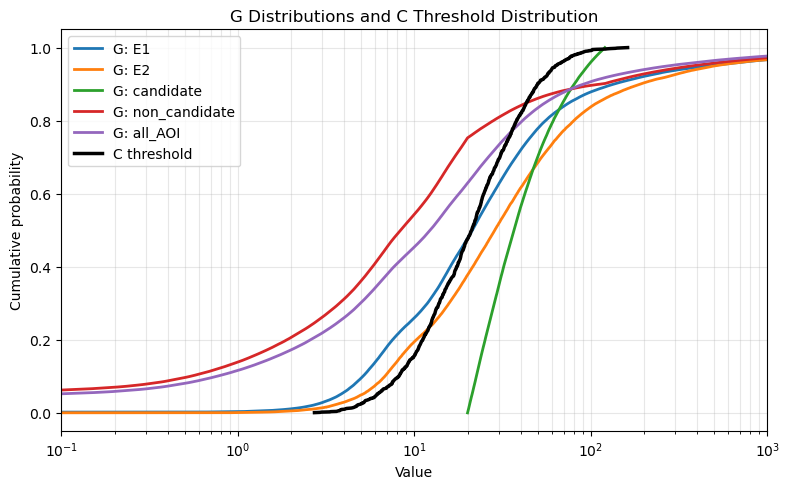

In [54]:
# --------------------
# Candidate and non-candidate cells
# --------------------
dem_diff_path = "/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated.tif"
dem_diff, _ = read_raster(dem_diff_path)

base_valid = (
    np.isfinite(G) &
    np.isfinite(dem_diff) &
    (G > 0)
)

candidate_cells = (
    base_valid &
    (G >= 20) &
    (G < 120) &
    (dem_diff < -0.01)
)

non_candidate_cells = base_valid & (~candidate_cells)

values_by_group["candidate"] = G[candidate_cells]
values_by_group["non_candidate"] = G[non_candidate_cells]
values_by_group["all_AOI"] = G[base_valid]

plt.figure(figsize=(8, 5))

for group, values in values_by_group.items():
    values = values[np.isfinite(values) & (values > 0)]
    x = np.sort(values)
    y = np.arange(1, len(x) + 1) / len(x)
    plt.plot(x, y, linewidth=2, label=f"G: {group}")

x = np.sort(C_values)
y = np.arange(1, len(x) + 1) / len(x)
plt.plot(x, y, color="black", linewidth=2.5, label="C threshold")

plt.xscale("log")
plt.xlabel("Value")
plt.ylabel("Cumulative probability")
plt.xlim(0.1, 1000)
plt.title("G Distributions and C Threshold Distribution")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

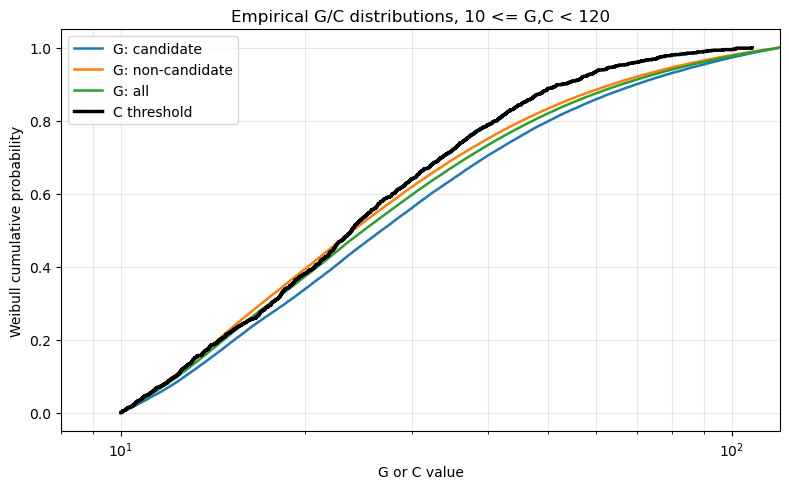

candidate cells: 103156
non-candidate cells: 170046
all cells: 273202


In [22]:
candidate_path = "/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated_lt_minus_0p05_no_channels_binary.tif"

C_MIN = 10
C_MAX = 120

candidate_raw, _ = read_raster(candidate_path)
candidate = candidate_raw == 1

G, profile = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))

valid_g_range = np.isfinite(G) & (G >= C_MIN) & (G < C_MAX)

G_candidate = G[valid_g_range & candidate]
G_non_candidate = G[valid_g_range & (~candidate)]
G_all = G[valid_g_range]

c_table = pd.read_csv("/mnt/c/Users/amehedi/Downloads/source_area_workflow/c_samples.csv")
C_values = c_table["C"].dropna().values
C_values = C_values[(C_values >= C_MIN) & (C_values < C_MAX)]

def weibull_cdf(values):
    x = np.sort(values[np.isfinite(values)])
    y = np.arange(1, len(x) + 1) / (len(x) + 1)
    return x, y

plt.figure(figsize=(8, 5))

for label, values in {
    "G: candidate": G_candidate,
    "G: non-candidate": G_non_candidate,
    "G: all": G_all,
    "C threshold": C_values,
}.items():
    x, y = weibull_cdf(values)
    plt.step(
        x, y,
        where="post",
        label=label,
        linewidth=2.5 if label == "C threshold" else 1.8,
        color="black" if label == "C threshold" else None,
    )

plt.xscale("log")
plt.xlim(8, C_MAX)
# plt.xlim(1, np.nanpercentile(G[np.isfinite(G)], 98))
plt.xlabel("G or C value")
plt.ylabel("Weibull cumulative probability")
plt.title(f"Empirical G/C distributions, {C_MIN} <= G,C < {C_MAX}")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("candidate cells:", len(G_candidate))
print("non-candidate cells:", len(G_non_candidate))
print("all cells:", len(G_all))

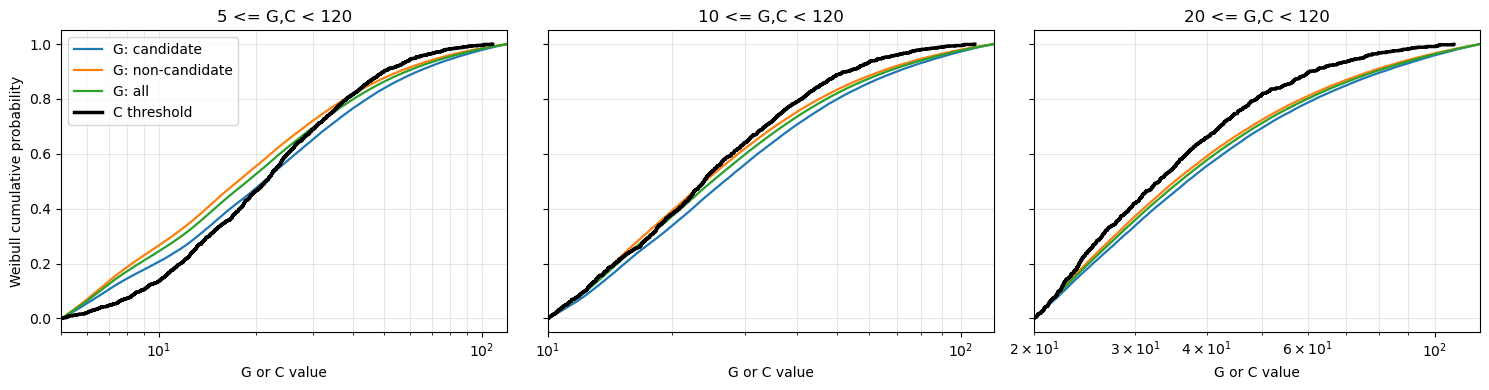

In [9]:
candidate_path = "/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated_lt_minus_0p05_no_channels_binary.tif"
C_MAX = 120
C_MINS = [5, 10, 20]

G, profile = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
candidate_raw, _ = read_raster(candidate_path)
candidate = candidate_raw == 1

c_table = pd.read_csv("/mnt/c/Users/amehedi/Downloads/source_area_workflow/c_samples.csv")
C_all = c_table["C"].dropna().values

def weibull_cdf(values):
    x = np.sort(values[np.isfinite(values)])
    y = np.arange(1, len(x) + 1) / (len(x) + 1)
    return x, y

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, C_MIN in zip(axes, C_MINS):
    valid_range = np.isfinite(G) & (G >= C_MIN) & (G < C_MAX)

    G_candidate = G[valid_range & candidate]
    G_non_candidate = G[valid_range & (~candidate)]
    G_all = G[valid_range]

    C_values = C_all[(C_all >= C_MIN) & (C_all < C_MAX)]

    for label, values in {
        "G: candidate": G_candidate,
        "G: non-candidate": G_non_candidate,
        "G: all": G_all,
        "C threshold": C_values,
    }.items():
        x, y = weibull_cdf(values)
        ax.step(
            x, y,
            where="post",
            label=label,
            linewidth=2.5 if label == "C threshold" else 1.6,
            color="black" if label == "C threshold" else None,
        )

    ax.set_xscale("log")
    ax.set_xlim(C_MIN, C_MAX)
    ax.set_title(f"{C_MIN} <= G,C < {C_MAX}")
    ax.set_xlabel("G or C value")
    ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel("Weibull cumulative probability")
axes[0].legend()
plt.tight_layout()
plt.show()

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster, write_raster

# --------------------
# 1. Load rasters
# --------------------
S, profile = read_raster(output_path(cfg, "slope", "slope.tif"))
a, _ = read_raster(output_path(cfg, "specific_catchment_area", "specific_catchment_area.tif"))
G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
dem_diff, _ = read_raster("/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated.tif")

# optional extra features
# burn, _ = read_raster("/mnt/c/Users/amehedi/Downloads/thomas/burn_severity.tif")
soil_texture, _ = read_raster("/mnt/c/Users/amehedi/Downloads/thomas/soil__texture.tif")

# --------------------
# 2. Make target
# --------------------
C_source = 20
C_channel = 120
dod_threshold = -0.277

Y = (
    (G >= C_source) &
    (G < C_channel) &
    (dem_diff < dod_threshold)
).astype("uint8")

# --------------------
# 3. Build feature table
# --------------------
valid = (
    np.isfinite(S) &
    np.isfinite(a) &
    np.isfinite(G) &
    # np.isfinite(burn) &
    np.isfinite(soil_texture)
)

X = pd.DataFrame({
    "slope": S[valid],
    "specific_area": a[valid],
    "G": G[valid],
    # "burn": burn[valid],
    "soil_texture": soil_texture[valid],
})

y = Y[valid]

print("positive cells:", int(y.sum()))
print("total cells:", len(y))

# --------------------
# 4. Balance data simply
# --------------------
pos = np.where(y == 1)[0]
neg = np.where(y == 0)[0]

rng = np.random.default_rng(42)
neg_sample = rng.choice(neg, size=min(len(neg), len(pos) * 3), replace=False)

idx = np.concatenate([pos, neg_sample])

X_train, X_test, y_train, y_test = train_test_split(
    X.iloc[idx],
    y[idx],
    test_size=0.3,
    random_state=42,
    stratify=y[idx]
)

# --------------------
# 5. Train RF
# --------------------
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(X_train, y_train)

pred = rf.predict(X_test)
print(classification_report(y_test, pred))

# --------------------
# 6. Feature importance
# --------------------
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

importance

positive cells: 22875
total cells: 579712
              precision    recall  f1-score   support

           0       0.87      0.87      0.87     20588
           1       0.61      0.60      0.61      6862

    accuracy                           0.81     27450
   macro avg       0.74      0.74      0.74     27450
weighted avg       0.80      0.81      0.80     27450



,feature,importance
2,G,0.580810
0,slope,0.238611
1,specific_area,0.126143
3,soil_texture,0.054436


In [ ]:
from pci_source_zones.inputs import write_raster

# create probability raster
prob = np.full(G.shape, np.nan, dtype="float32")

# predict RF probability for all valid cells
prob[valid] = rf.predict_proba(X)[:, 1]

# export
out_path = "/mnt/c/Users/amehedi/Downloads/source_area_workflow/rf_source_probability_C20.tif"

write_raster(out_path, prob, profile)

print("saved:", out_path)

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/rf_source_probability_C20.tif


In [ ]:
from pci_source_zones.inputs import write_raster

# probability threshold
p_threshold = 0.5

# class raster: 1 = predicted source, 0 = predicted non-source
rf_class = np.zeros(G.shape, dtype="uint8")
rf_class[valid] = (prob[valid] >= p_threshold).astype("uint8")

# save
out_path = "/mnt/c/Users/amehedi/Downloads/source_area_workflow/rf_source_class_C20.tif"

write_binary_raster(out_path, rf_class, profile)

print("saved:", out_path)
print("predicted source cells:", int(rf_class.sum()))

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/rf_source_class_C20.tif
predicted source cells: 91197


In [46]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster, write_raster
from pci_source_zones.physics.source_area import write_binary_raster

# features
S, profile = read_raster(output_path(cfg, "slope", "slope.tif"))
a, _ = read_raster(output_path(cfg, "specific_catchment_area", "specific_catchment_area.tif"))
G, _ = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))

burn, _ = read_raster("/mnt/c/Users/amehedi/Downloads/thomas/burn__severity.tif")
soil, _ = read_raster("/mnt/c/Users/amehedi/Downloads/thomas/soil__texture.tif")

# target raster: change path if needed
target_path = "/mnt/c/Users/amehedi/Downloads/source_area_workflow/ml_target_C20.tif"
Y, _ = read_raster(target_path)

Y = (Y == 1).astype("float32")

In [47]:
def normalize(x):
    x = x.astype("float32")
    lo = np.nanpercentile(x, 2)
    hi = np.nanpercentile(x, 98)
    x = (x - lo) / (hi - lo)
    x = np.clip(x, 0, 1)
    return np.nan_to_num(x, nan=0)

X = np.stack([
    normalize(S),
    normalize(a),
    normalize(G),
    normalize(burn),
    normalize(soil),
])

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("positive pixels:", int(Y.sum()))

X shape: (5, 835, 716)
Y shape: (835, 716)
positive pixels: 44930


/tmp/ipykernel_2780/1322402836.py:5: RuntimeWarning: invalid value encountered in divide
  x = (x - lo) / (hi - lo)


In [48]:
class RasterPatchDataset(Dataset):
    def __init__(self, X, Y, patch_size=64, n_patches=2000):
        self.X = X
        self.Y = Y
        self.patch_size = patch_size
        self.n_patches = n_patches
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return self.n_patches

    def __getitem__(self, idx):
        ps = self.patch_size
        h, w = self.Y.shape

        row = self.rng.integers(0, h - ps)
        col = self.rng.integers(0, w - ps)

        x_patch = self.X[:, row:row+ps, col:col+ps]
        y_patch = self.Y[row:row+ps, col:col+ps]

        return (
            torch.tensor(x_patch, dtype=torch.float32),
            torch.tensor(y_patch[None, :, :], dtype=torch.float32)
        )

train_ds = RasterPatchDataset(X, Y, patch_size=64, n_patches=3000)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)

In [49]:
class RasterPatchDataset(Dataset):
    def __init__(self, X, Y, patch_size=64, n_patches=2000):
        self.X = X
        self.Y = Y
        self.patch_size = patch_size
        self.n_patches = n_patches
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return self.n_patches

    def __getitem__(self, idx):
        ps = self.patch_size
        h, w = self.Y.shape

        row = self.rng.integers(0, h - ps)
        col = self.rng.integers(0, w - ps)

        x_patch = self.X[:, row:row+ps, col:col+ps]
        y_patch = self.Y[row:row+ps, col:col+ps]

        return (
            torch.tensor(x_patch, dtype=torch.float32),
            torch.tensor(y_patch[None, :, :], dtype=torch.float32)
        )

train_ds = RasterPatchDataset(X, Y, patch_size=64, n_patches=3000)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)

In [52]:
import torch
import torch.nn as nn

class Block(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    def __init__(self, in_ch):
        super().__init__()

        self.b1 = Block(in_ch, 16)
        self.b2 = Block(16, 32)
        self.b3 = Block(32, 64)

        self.pool = nn.MaxPool2d(2)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.b4 = Block(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.b5 = Block(32, 16)

        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        x1 = self.b1(x)
        x2 = self.b2(self.pool(x1))
        x3 = self.b3(self.pool(x2))

        y = self.up2(x3)
        y = self.b4(torch.cat([y, x2], dim=1))

        y = self.up1(y)
        y = self.b5(torch.cat([y, x1], dim=1))

        return self.out(y)

In [53]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = UNet(in_ch=X.shape[0]).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

pos = Y.sum()
neg = Y.size - pos

pos_weight = torch.tensor([neg / max(pos, 1)], dtype=torch.float32).to(device)

loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print("device:", device)
print("positive pixels:", int(pos))
print("negative pixels:", int(neg))

device: cuda
positive pixels: 44930
negative pixels: 552930


In [54]:
for epoch in range(5):
    model.train()
    losses = []

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    print("epoch:", epoch + 1, "loss:", np.mean(losses))

epoch: 1 loss: 1.07566108094885
epoch: 2 loss: 0.9655029034995019
epoch: 3 loss: 0.8686675892231313
epoch: 4 loss: 0.7966354918923784
epoch: 5 loss: 0.766051249142657


In [56]:
model.eval()

h, w = Y.shape

# make size divisible by 4
h2 = (h // 4) * 4
w2 = (w // 4) * 4

X_crop = X[:, :h2, :w2]

with torch.no_grad():
    x_tensor = torch.tensor(X_crop[None, :, :, :], dtype=torch.float32).to(device)
    logits = model(x_tensor)
    prob_crop = torch.sigmoid(logits)[0, 0].cpu().numpy().astype("float32")

# put crop prediction back into full-size raster
prob = np.full(Y.shape, np.nan, dtype="float32")
prob[:h2, :w2] = prob_crop

print("prediction shape:", prob.shape)

prediction shape: (835, 716)


In [64]:
from pci_source_zones.inputs import write_raster
from pci_source_zones.physics.source_area import write_binary_raster

prob_path = "/mnt/c/Users/amehedi/Downloads/source_area_workflow/unet_source_probability_C20.tif"
write_raster(prob_path, prob, profile)

unet_class = (prob >= 0.85).astype("uint8")

class_path = "/mnt/c/Users/amehedi/Downloads/source_area_workflow/unet_source_class_C20.tif"
write_binary_raster(class_path, unet_class, profile)

print("saved:", prob_path)
print("saved:", class_path)
print("predicted source pixels:", int(unet_class.sum()))

saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/unet_source_probability_C20.tif
saved: /mnt/c/Users/amehedi/Downloads/source_area_workflow/unet_source_class_C20.tif
predicted source pixels: 59670


In [65]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

p_threshold = 0.85   # change if needed

pred = (prob >= p_threshold).astype("uint8")

mask = np.isfinite(prob)

y_true = Y[mask].astype("uint8")
y_pred = pred[mask].astype("uint8")

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred))

print()
print(classification_report(y_true, y_pred))

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1:", f1_score(y_true, y_pred, zero_division=0))

Confusion matrix:
[[516084  34698]
 [ 19958  24972]]

              precision    recall  f1-score   support

           0       0.96      0.94      0.95    550782
           1       0.42      0.56      0.48     44930

    accuracy                           0.91    595712
   macro avg       0.69      0.75      0.71    595712
weighted avg       0.92      0.91      0.91    595712

Accuracy: 0.9082509669101848
Precision: 0.4185017596782303
Recall: 0.5557979078566659
F1: 0.47747609942638625


In [67]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score, balanced_accuracy_score, matthews_corrcoef

from pci_source_zones.config import output_path
from pci_source_zones.inputs import read_raster

# load G and DoD
G, profile = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
dem_diff, _ = read_raster(cfg["paths"]["dem_diff"])

# observed erosion target from DoD
observed = dem_diff < -0.277

# valid cells
valid = np.isfinite(G) & np.isfinite(dem_diff)

# C values to test
C_values = [5, 8, 10, 15, 20, 25, 30, 40, 50, 60, 70, 90, 100, 120]

rows = []

for C in C_values:
    # prediction from threshold
    predicted = G >= C

    y_true = observed[valid].astype("uint8")
    y_pred = predicted[valid].astype("uint8")

    rows.append({
        "C": C,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "iou": jaccard_score(y_true, y_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "predicted_cells": int(predicted[valid].sum()),
        "observed_cells": int(observed[valid].sum()),
        "area_ratio": predicted[valid].sum() / max(observed[valid].sum(), 1),
    })

score_table = pd.DataFrame(rows)
score_table

,C,precision,recall,f1,iou,balanced_accuracy,mcc,predicted_cells,observed_cells,area_ratio
0,5,0.253460,0.905733,0.396081,0.246945,0.629362,0.223246,368883,103228,3.573478
1,8,0.272297,0.823895,0.409315,0.257320,0.644943,0.233658,312339,103228,3.025720
2,10,0.281535,0.786686,0.414670,0.261567,0.649893,0.238625,288447,103228,2.794271
3,15,0.303250,0.693378,0.421956,0.267392,0.653500,0.244773,236030,103228,2.286492
4,20,0.318227,0.604642,0.416989,0.263415,0.645235,0.238340,196137,103228,1.900037
5,25,0.330576,0.528355,0.406695,0.255252,0.634432,0.230011,164988,103228,1.598287
6,30,0.340158,0.465629,0.393125,0.244652,0.623284,0.220855,141305,103228,1.368863
7,40,0.354384,0.370965,0.362485,0.221363,0.603529,0.203535,108058,103228,1.046790
8,50,0.365606,0.309441,0.335187,0.201336,0.589609,0.191274,87370,103228,0.846379
9,60,0.373581,0.267718,0.311912,0.184772,0.579422,0.181506,73976,103228,0.716627


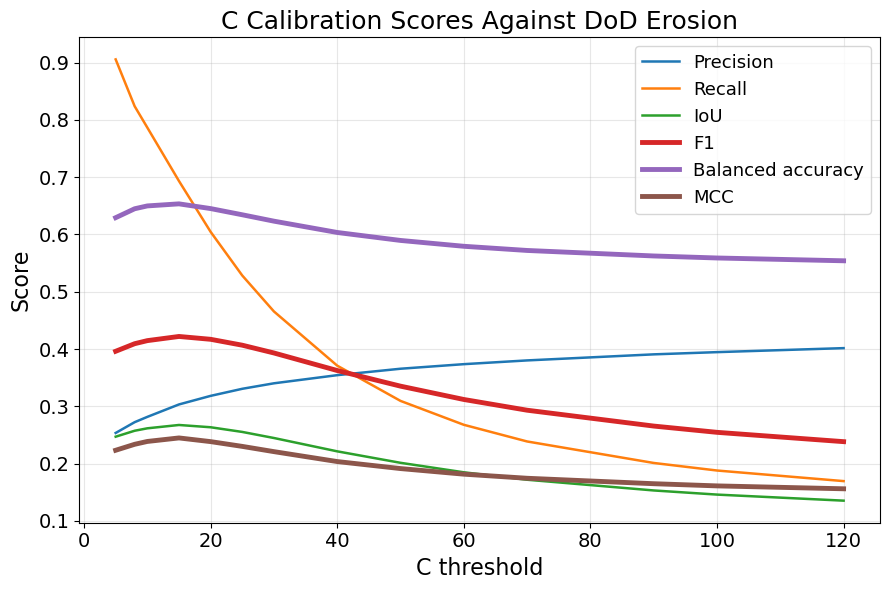

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(score_table["C"], score_table["precision"], label="Precision", linewidth=1.8)
plt.plot(score_table["C"], score_table["recall"], label="Recall", linewidth=1.8)
plt.plot(score_table["C"], score_table["iou"], label="IoU", linewidth=1.8)

plt.plot(score_table["C"], score_table["f1"], label="F1", linewidth=3.5)
plt.plot(score_table["C"], score_table["balanced_accuracy"], label="Balanced accuracy", linewidth=3.5)
plt.plot(score_table["C"], score_table["mcc"], label="MCC", linewidth=3.5)

plt.xlabel("C threshold", fontsize=16)
plt.ylabel("Score", fontsize=16)
plt.title("C Calibration Scores Against DoD Erosion", fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=13)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

from pci_source_zones.inputs import read_raster

# --------------------
# 0. Inputs to change
# --------------------
DATA = Path("/mnt/c/Users/amehedi/Downloads/thomas")
GEE_DATA = Path("/mnt/c/Users/amehedi/Downloads/thomas/gee_lai_ndvi_et")

target_path = Path("/mnt/c/Users/amehedi/Downloads/source_area_workflow/ml_target_C20_lt_channel_C120_dod_lt_minus_0p277_binary.tif")

feature_files = {
    # existing local layers
    # "burn_severity": DATA / "burn__severity.tif",
    "soil_texture": DATA / "soil__texture.tif",
    "soil_thickness": DATA / "soil__thickness.tif",
    "soil_density": DATA / "soil__density.tif",
    "sand_total": DATA / "sand__total.tif",
    "silt_total": DATA / "silt__total.tif",
    "clay_total": DATA / "clay__total.tif",
    "porosity": DATA / "porosity.tif",
    # "pH": DATA / "pH.tif",
    "field_capacity": DATA / "field__capacity.tif",
    "saturated_water_content": DATA / "saturated__water_content.tif",
    "soil_transmissivity": DATA / "soil__transmissivity.tif",
    "saturated_hydraulic_conductivity": DATA / "soil__saturated_hydraulic_conductivity.tif",
    "landcover": DATA / "landcover.tif",

    # GEE change layers: update filenames to your exported *_aligned.tif files
    "ndvi_diff": GEE_DATA / "NDVI_median_pre_2017-10-01_to_2017-10-30_post_2019-12-01_to_2019-12-30_diff_post_minus_pre_aligned.tif",
    "et_diff": GEE_DATA / "ET_median_pre_2017-10-01_to_2017-10-30_post_2019-12-01_to_2019-12-30_diff_post_minus_pre_aligned.tif",
}

RANDOM_SEED = 42
NEGATIVE_TO_POSITIVE_RATIO = 3
TEST_SIZE = 0.30

# --------------------
# 1. Helpers
# --------------------
def check_same_grid(path, reference_profile):
    with rasterio.open(path) as src:
        same_shape = (src.height, src.width) == (
            reference_profile["height"],
            reference_profile["width"],
        )
        same_crs = src.crs == reference_profile["crs"]
        same_transform = src.transform.almost_equals(reference_profile["transform"])

    if not (same_shape and same_crs and same_transform):
        raise ValueError(
            f"Raster is not aligned with target grid: {path}\n"
            f"same_shape={same_shape}, same_crs={same_crs}, same_transform={same_transform}"
        )

# --------------------
# 2. Read target
# --------------------
target_raw, profile = read_raster(target_path)
target_valid = np.isfinite(target_raw)
Y = (target_raw == 1).astype("uint8")

# --------------------
# 3. Read features
# --------------------
features = {}
valid = target_valid.copy()

for name, path in feature_files.items():
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Missing feature '{name}': {path}")

    check_same_grid(path, profile)

    arr, _ = read_raster(path)
    features[name] = arr
    valid &= np.isfinite(arr)

# --------------------
# 4. Build table
# --------------------
X = pd.DataFrame({
    name: arr[valid]
    for name, arr in features.items()
})

y = Y[valid]

print("features:", list(X.columns))
print("total samples:", len(y))
print("positive source cells:", int(y.sum()))
print("negative source cells:", int((y == 0).sum()))

# --------------------
# 5. Balance negatives
# --------------------
pos = np.where(y == 1)[0]
neg = np.where(y == 0)[0]

rng = np.random.default_rng(RANDOM_SEED)
neg_sample = rng.choice(
    neg,
    size=min(len(neg), len(pos) * NEGATIVE_TO_POSITIVE_RATIO),
    replace=False,
)

idx = np.concatenate([pos, neg_sample])
rng.shuffle(idx)

# --------------------
# 6. Train/test split
# --------------------
X_train, X_test, y_train, y_test = train_test_split(
    X.iloc[idx],
    y[idx],
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=y[idx],
)

# --------------------
# 7. Train RF
# --------------------
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_SEED,
    class_weight="balanced",
    n_jobs=-1,
)

rf.fit(X_train, y_train)

pred = rf.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))

# --------------------
# 8. Feature importance
# --------------------
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf.feature_importances_,
}).sort_values("importance", ascending=False)

importance

features: ['soil_texture', 'soil_thickness', 'soil_density', 'sand_total', 'silt_total', 'clay_total', 'porosity', 'field_capacity', 'saturated_water_content', 'soil_transmissivity', 'saturated_hydraulic_conductivity', 'landcover', 'ndvi_diff', 'et_diff']
total samples: 521961
positive source cells: 44463
negative source cells: 477498
              precision    recall  f1-score   support

           0       0.88      0.92      0.90     40017
           1       0.71      0.61      0.65     13339

    accuracy                           0.84     53356
   macro avg       0.79      0.76      0.78     53356
weighted avg       0.83      0.84      0.84     53356



,feature,importance
12,ndvi_diff,0.192000
9,soil_transmissivity,0.174332
13,et_diff,0.143430
1,soil_thickness,0.139441
10,saturated_hydraulic_conductivity,0.120143
8,saturated_water_content,0.049211
11,landcover,0.048564
3,sand_total,0.037206
5,clay_total,0.032876
4,silt_total,0.025693


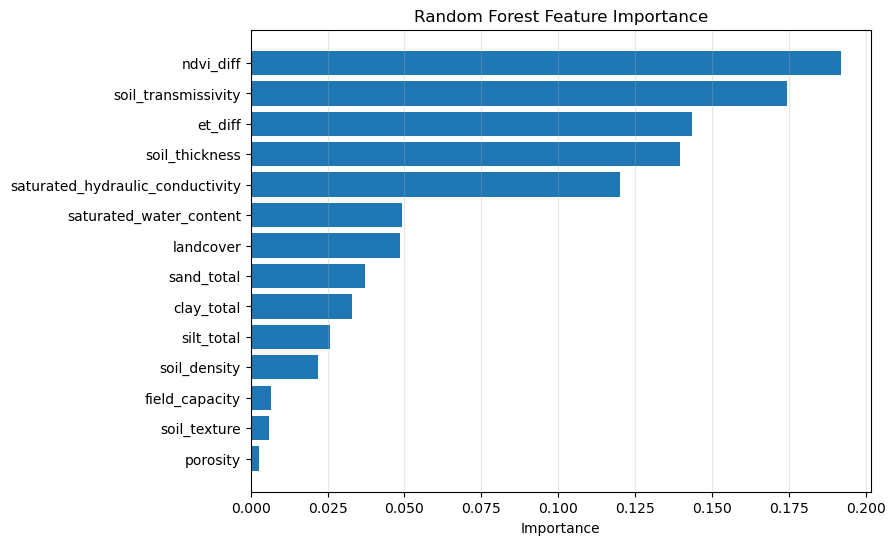

In [34]:
plt.figure(figsize=(8, 6))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")
plt.grid(True, axis="x", alpha=0.3)
plt.show()

ValueError: Feature 'burn_severity' not in feature_names

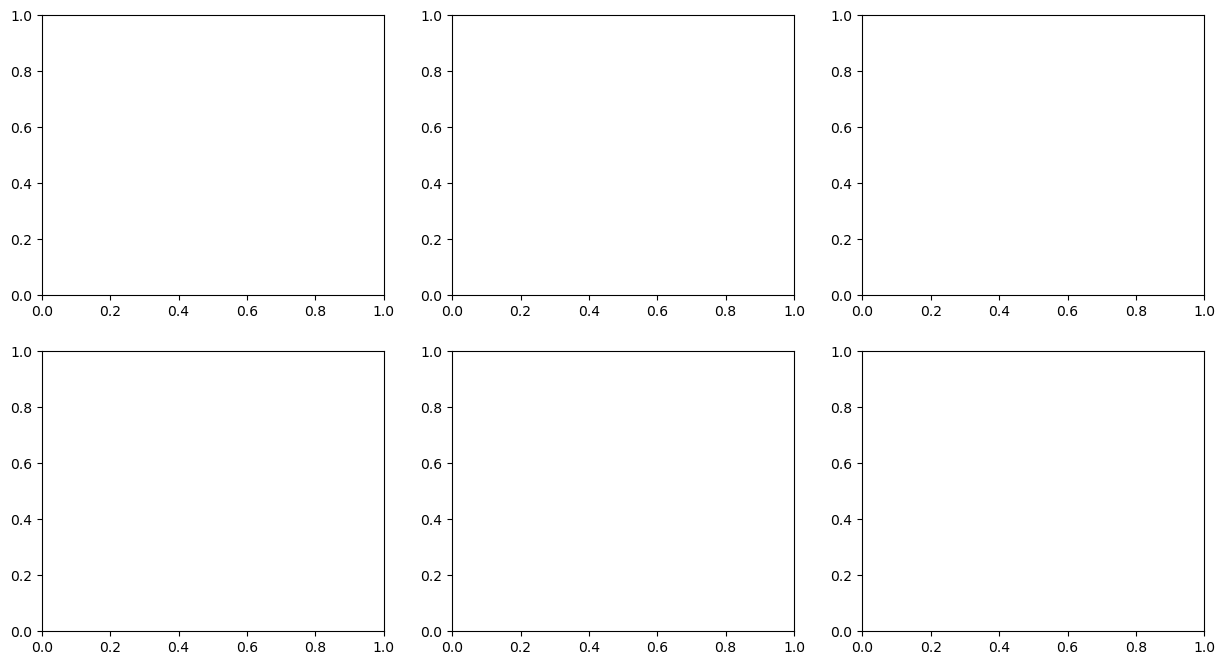

In [19]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

# choose features to plot
pdp_features = [
    "burn_severity",
    "soil_texture",
    "soil_thickness",
    "sand_total",
    "clay_total",
    "porosity",
]

fig, ax = plt.subplots(2, 3, figsize=(15, 8))

PartialDependenceDisplay.from_estimator(
    rf,
    X_train,
    features=pdp_features,
    ax=ax.ravel(),
    grid_resolution=30
)

plt.suptitle("Partial Dependence Plots - Random Forest", fontsize=16)
plt.tight_layout()
plt.show()

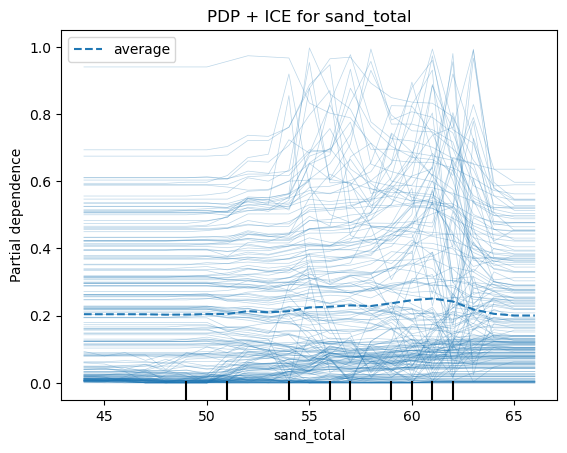

In [22]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

feature_name = "sand_total"   

PartialDependenceDisplay.from_estimator(
    rf,
    X_train,
    features=[feature_name],
    kind="both",          # "average" for PDP only, "individual" for ICE only, "both" for both
    target=1,             # class 1 = source candidate
    subsample=200,
    grid_resolution=30
)

plt.title(f"PDP + ICE for {feature_name}")
plt.show()

In [24]:
import geopandas as gpd
import numpy as np
import pandas as pd
from rasterio.features import geometry_mask

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# --------------------
# 1. Inputs
# --------------------
poly_path = "/mnt/c/Users/amehedi/Downloads/dunne_lithology_polygons_unlabeled.gpkg"

TRAIN_POLY_ID = 3
TEST_POLY_ID = 4
RANDOM_SEED = 42

# If you used the new target raster, valid should already exclude nodata.
# This line is extra protection if Y_raw exists from the target-loading cell.
if "Y_raw" in globals():
    valid = valid & np.isfinite(Y_raw)

# --------------------
# 2. Load polygons and match raster CRS
# --------------------
polys = gpd.read_file(poly_path)

if polys.crs != profile["crs"]:
    polys = polys.to_crs(profile["crs"])

train_geom = polys.loc[polys["poly_id"] == TRAIN_POLY_ID, "geometry"]
test_geom = polys.loc[polys["poly_id"] == TEST_POLY_ID, "geometry"]

if train_geom.empty:
    raise ValueError(f"No polygon found for TRAIN_POLY_ID={TRAIN_POLY_ID}")
if test_geom.empty:
    raise ValueError(f"No polygon found for TEST_POLY_ID={TEST_POLY_ID}")

# --------------------
# 3. Make train/test masks
# --------------------
train_mask = geometry_mask(
    train_geom,
    out_shape=Y.shape,
    transform=profile["transform"],
    invert=True,
)

test_mask = geometry_mask(
    test_geom,
    out_shape=Y.shape,
    transform=profile["transform"],
    invert=True,
)

train_valid = valid & train_mask
test_valid = valid & test_mask

# --------------------
# 4. Build train/test tables
# --------------------
X_train = pd.DataFrame({
    name: arr[train_valid]
    for name, arr in features.items()
})

y_train = Y[train_valid]

X_test = pd.DataFrame({
    name: arr[test_valid]
    for name, arr in features.items()
})

y_test = Y[test_valid]

print("features:", list(X_train.columns))
print("train cells:", len(y_train), "positive:", int(y_train.sum()), "negative:", int((y_train == 0).sum()))
print("test cells:", len(y_test), "positive:", int(y_test.sum()), "negative:", int((y_test == 0).sum()))

if len(np.unique(y_train)) < 2:
    raise ValueError("Training polygon has only one class. Choose another polygon or merge training polygons.")
if len(np.unique(y_test)) < 2:
    print("Warning: test polygon has only one class, classification metrics will be limited.")

# --------------------
# 5. Train RF
# --------------------
rf_poly = RandomForestClassifier(
    n_estimators=10,
    random_state=RANDOM_SEED,
    class_weight="balanced",
    n_jobs=-1,
)

rf_poly.fit(X_train, y_train)

# --------------------
# 6. Test on polygon 4
# --------------------
pred = rf_poly.predict(X_test)

print("confusion matrix:")
print(confusion_matrix(y_test, pred))

print()
print(classification_report(y_test, pred, zero_division=0))

# --------------------
# 7. Feature importance
# --------------------
importance_poly = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_poly.feature_importances_,
}).sort_values("importance", ascending=False)

importance_poly

features: ['soil_texture', 'soil_thickness', 'soil_density', 'sand_total', 'silt_total', 'clay_total', 'porosity', 'field_capacity', 'saturated_water_content', 'soil_transmissivity', 'saturated_hydraulic_conductivity', 'landcover', 'ndvi_diff', 'et_diff']
train cells: 82111 positive: 15240 negative: 66871
test cells: 33913 positive: 5806 negative: 28107
confusion matrix:
[[27941   166]
 [ 5756    50]]

              precision    recall  f1-score   support

           0       0.83      0.99      0.90     28107
           1       0.23      0.01      0.02      5806

    accuracy                           0.83     33913
   macro avg       0.53      0.50      0.46     33913
weighted avg       0.73      0.83      0.75     33913



,feature,importance
13,et_diff,0.213831
12,ndvi_diff,0.208457
10,saturated_hydraulic_conductivity,0.178676
9,soil_transmissivity,0.171067
1,soil_thickness,0.091317
8,saturated_water_content,0.044794
3,sand_total,0.027698
4,silt_total,0.018937
5,clay_total,0.018313
2,soil_density,0.018003


In [30]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

# --------------------
# 1. RF tuning controls
# --------------------
rf_params = {
    "n_estimators": [5, 10, 20, 30, 40, 50, 60, 70, 80, 100, 120, 150, 200],
    "max_depth": [None, 5, 10, 20, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", None],
    "class_weight": ["balanced", "balanced_subsample"],
}

RANDOM_SEED = 42
SCORING = "f1"              # good for positive source class
USE_RANDOM_SEARCH = True    # False = full grid search, much slower
N_ITER = 500                # used only for randomized search
CV_FOLDS = 3

# --------------------
# 2. Safety checks
# --------------------
print("train cells:", len(y_train), "positive:", int(y_train.sum()), "negative:", int((y_train == 0).sum()))
print("test cells:", len(y_test), "positive:", int(y_test.sum()), "negative:", int((y_test == 0).sum()))

if len(np.unique(y_train)) < 2:
    raise ValueError("Training polygon has only one class. Cannot tune classifier.")

# --------------------
# 3. Tune only inside train polygon
# --------------------
base_rf = RandomForestClassifier(
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)

if USE_RANDOM_SEARCH:
    search = RandomizedSearchCV(
        estimator=base_rf,
        param_distributions=rf_params,
        n_iter=N_ITER,
        scoring=SCORING,
        cv=cv,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=2,
        refit=True,
    )
else:
    search = GridSearchCV(
        estimator=base_rf,
        param_grid=rf_params,
        scoring=SCORING,
        cv=cv,
        n_jobs=-1,
        verbose=2,
        refit=True,
    )

search.fit(X_train, y_train)

print("best CV score:", search.best_score_)
print("best params:")
print(search.best_params_)

# --------------------
# 4. Final test on held-out polygon
# --------------------
rf_tuned = search.best_estimator_

test_pred = rf_tuned.predict(X_test)

print("held-out polygon confusion matrix:")
print(confusion_matrix(y_test, test_pred))

print()
print(classification_report(y_test, test_pred, zero_division=0))

# --------------------
# 5. Feature importance
# --------------------
importance_tuned = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_tuned.feature_importances_,
}).sort_values("importance", ascending=False)

importance_tuned

train cells: 82111 positive: 15240 negative: 66871
test cells: 33913 positive: 5806 negative: 28107
Fitting 3 folds for each of 500 candidates, totalling 1500 fits


[CV] END class_weight=balanced_subsample, max_depth=None, max_features=log2, min_samples_leaf=8, min_samples_split=5, n_estimators=10; total time=   3.6s
[CV] END class_weight=balanced_subsample, max_depth=None, max_features=log2, min_samples_leaf=8, min_samples_split=5, n_estimators=10; total time=   3.7s
[CV] END class_weight=balanced_subsample, max_depth=None, max_features=log2, min_samples_leaf=8, min_samples_split=5, n_estimators=10; total time=   3.9s
[CV] END class_weight=balanced, max_depth=5, max_features=sqrt, min_samples_leaf=2, min_samples_split=10, n_estimators=50; total time=   4.0s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=70; total time=   8.0s
[CV] END class_weight=balanced, max_depth=10, max_features=log2, min_samples_leaf=8, min_samples_split=10, n_estimators=100; total time=   8.4s
[CV] END class_weight=balanced, max_depth=10, max_features=log2, min_samples_leaf=8, min_samples_split=10, 

/home/abdullah/miniconda3/envs/ml_debris/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END class_weight=balanced, max_depth=None, max_features=None, min_samples_leaf=4, min_samples_split=10, n_estimators=5; total time=   9.1s
[CV] END class_weight=balanced_subsample, max_depth=10, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=10; total time=   4.0s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=120; total time=  14.2s
[CV] END class_weight=balanced_subsample, max_depth=10, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=10; total time=   4.4s
[CV] END class_weight=balanced_subsample, max_depth=10, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=10; total time=   4.4s
[CV] END class_weight=balanced, max_depth=None, max_features=None, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=  34.1s
[CV] END class_weight=balanced, max_depth=None, max_features=None, min_samples_leaf=2, min_samples_split=5, n_

,feature,importance
13,et_diff,0.194301
10,saturated_hydraulic_conductivity,0.180897
12,ndvi_diff,0.180504
9,soil_transmissivity,0.160091
1,soil_thickness,0.100173
8,saturated_water_content,0.059336
3,sand_total,0.034082
5,clay_total,0.027941
4,silt_total,0.025592
2,soil_density,0.025330


In [31]:
print("Best CV score:", search.best_score_)
print("Best params:")
print(search.best_params_)

Best CV score: 0.48324458914124024
Best params:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced_subsample'}


In [32]:
for key, value in search.best_params_.items():
    print(f"{key}: {value}")

print(f"Best {SCORING} score: {search.best_score_:.4f}")

n_estimators: 200
min_samples_split: 5
min_samples_leaf: 8
max_features: log2
max_depth: None
class_weight: balanced_subsample
Best f1 score: 0.4832


In [33]:
test_pred = rf_tuned.predict(X_test)
print(classification_report(y_test, test_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.85      0.84      0.84     28107
           1       0.26      0.27      0.26      5806

    accuracy                           0.74     33913
   macro avg       0.55      0.55      0.55     33913
weighted avg       0.75      0.74      0.74     33913



In [28]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results = cv_results.sort_values("rank_test_score")

cv_results[
    ["rank_test_score", "mean_test_score", "std_test_score", "params"]
].head(10)

,rank_test_score,mean_test_score,std_test_score,params
64,1,0.483245,0.001836,"{'n_estimators': 200, 'min_samples_split': 5, ..."
22,2,0.481455,0.001144,"{'n_estimators': 100, 'min_samples_split': 10,..."
61,3,0.481010,0.000996,"{'n_estimators': 100, 'min_samples_split': 2, ..."
23,4,0.479709,0.001318,"{'n_estimators': 100, 'min_samples_split': 10,..."
46,5,0.479183,0.000567,"{'n_estimators': 120, 'min_samples_split': 5, ..."
57,6,0.477914,0.001718,"{'n_estimators': 50, 'min_samples_split': 5, '..."
29,7,0.477134,0.002006,"{'n_estimators': 60, 'min_samples_split': 5, '..."
16,8,0.476979,0.003094,"{'n_estimators': 120, 'min_samples_split': 5, ..."
27,9,0.476229,0.002020,"{'n_estimators': 70, 'min_samples_split': 5, '..."
11,10,0.476012,0.001777,"{'n_estimators': 40, 'min_samples_split': 10, ..."


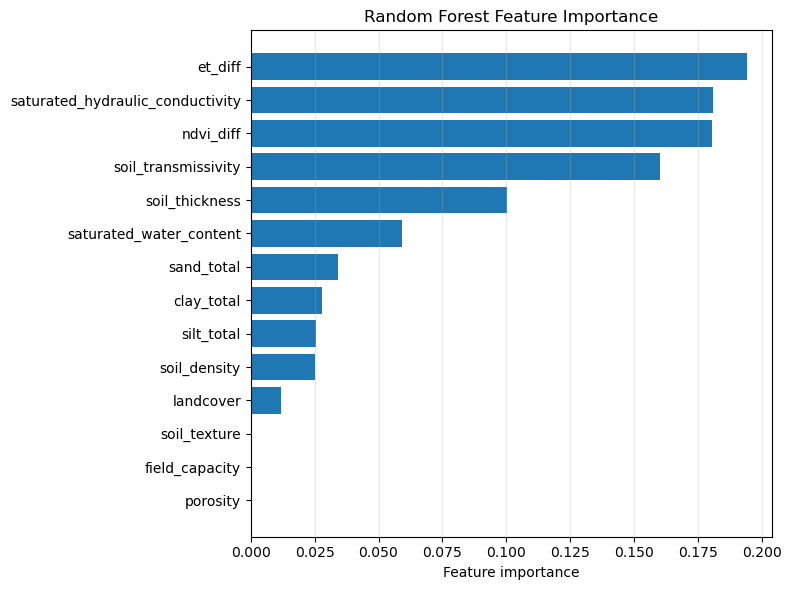

In [35]:
import matplotlib.pyplot as plt

# Plot top N features
TOP_N = 20

plot_df = importance_tuned.head(TOP_N).sort_values("importance")

plt.figure(figsize=(8, 6))
plt.barh(plot_df["feature"], plot_df["importance"])
plt.xlabel("Feature importance")
plt.title("Random Forest Feature Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

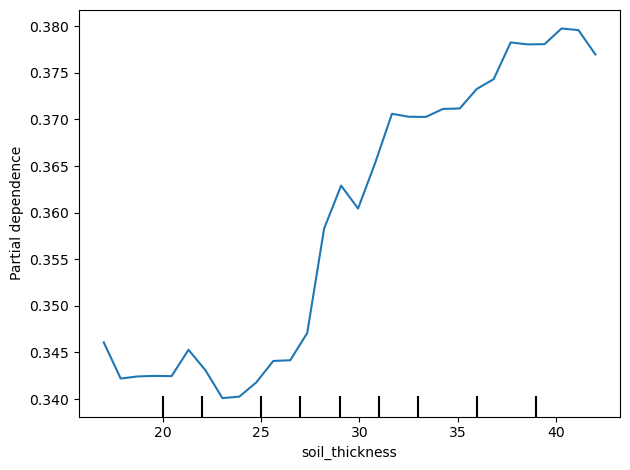

In [43]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

features_to_plot = ["soil_thickness"]  # change names if yours differ

PartialDependenceDisplay.from_estimator(
    rf_tuned,
    X_train,
    features=features_to_plot,
    target=1,
    grid_resolution=30,
)

plt.tight_layout()
plt.show()

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
import pandas as pd

selected_features = ["et_diff", "ndvi_diff", "soil_thickness"]

logit = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

logit.fit(X_train[selected_features], y_train)

pred = logit.predict(X_test[selected_features])
print(classification_report(y_test, pred, zero_division=0))

coef = pd.DataFrame({
    "feature": selected_features,
    "coef_standardized": logit.named_steps["model"].coef_[0]
}).sort_values("coef_standardized", ascending=False)

coef

              precision    recall  f1-score   support

           0       0.90      0.58      0.70     28107
           1       0.25      0.68      0.37      5806

    accuracy                           0.60     33913
   macro avg       0.57      0.63      0.54     33913
weighted avg       0.79      0.60      0.65     33913



,feature,coef_standardized
2,soil_thickness,0.064984
1,ndvi_diff,-0.156450
0,et_diff,-0.271980


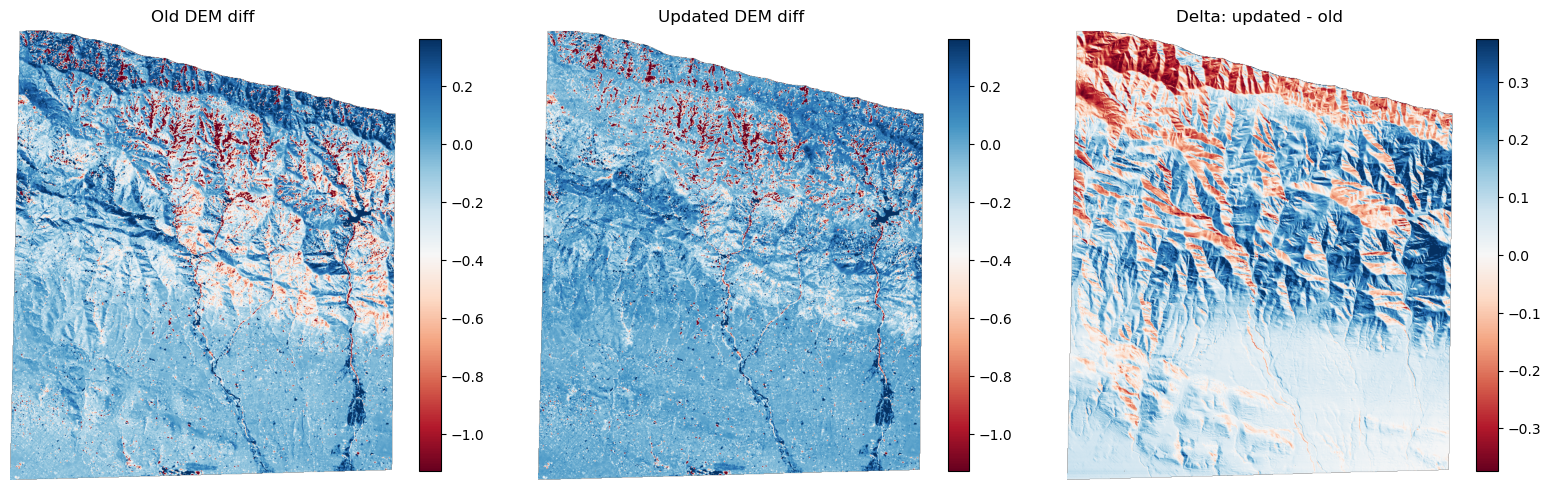

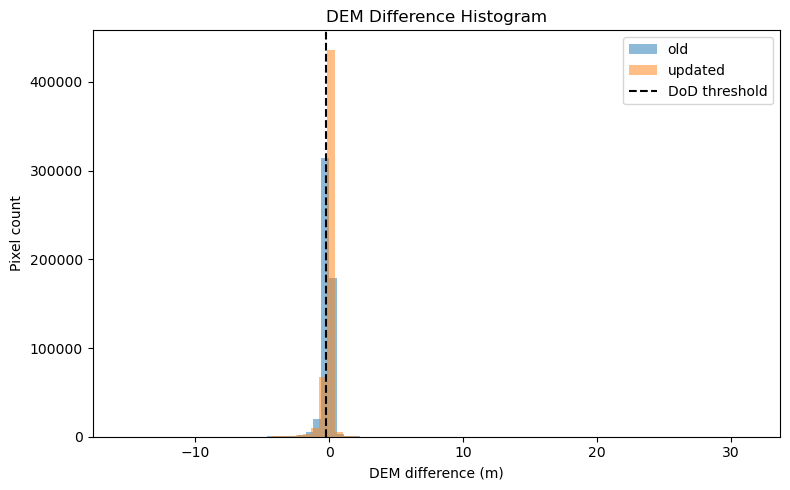

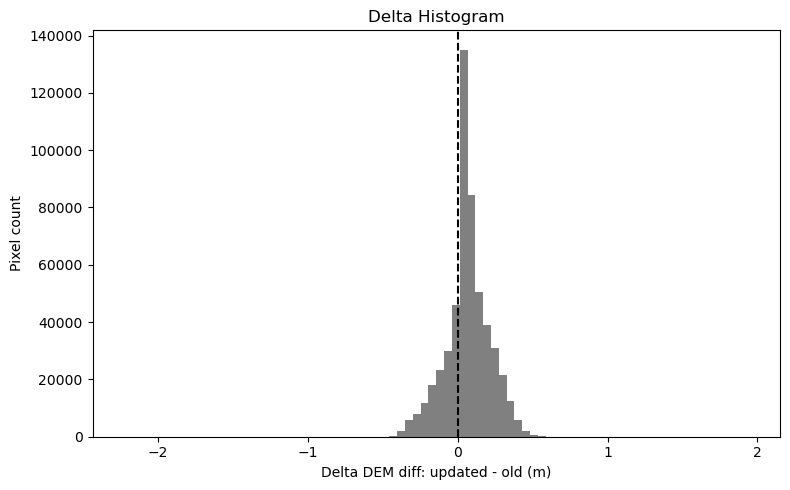

old mean: -0.13128091818471238
updated mean: -0.06687754468266409
delta mean: 0.06440338
delta min/max: -2.2300792 1.9427141


In [9]:
import numpy as np
import matplotlib.pyplot as plt

from pci_source_zones.inputs import read_raster

old_path = "/mnt/c/Users/amehedi/Downloads/thomas/dem_diff.tif"
new_path = "/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated.tif"

old, profile = read_raster(old_path)
new, _ = read_raster(new_path)

valid = np.isfinite(old) & np.isfinite(new)

delta = np.full(old.shape, np.nan, dtype="float32")
delta[valid] = new[valid] - old[valid]

# --------------------
# 1. Spatial maps
# --------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

vmin = np.nanpercentile(np.r_[old[valid], new[valid]], 2)
vmax = np.nanpercentile(np.r_[old[valid], new[valid]], 98)

im0 = axes[0].imshow(old, cmap="RdBu", vmin=vmin, vmax=vmax)
axes[0].set_title("Old DEM diff")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(new, cmap="RdBu", vmin=vmin, vmax=vmax)
axes[1].set_title("Updated DEM diff")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

dv = np.nanpercentile(np.abs(delta[valid]), 98)
im2 = axes[2].imshow(delta, cmap="RdBu", vmin=-dv, vmax=dv)
axes[2].set_title("Delta: updated - old")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

# --------------------
# 2. Histograms
# --------------------
plt.figure(figsize=(8, 5))
plt.hist(old[valid], bins=80, alpha=0.5, label="old")
plt.hist(new[valid], bins=80, alpha=0.5, label="updated")
plt.axvline(-0.277, color="black", linestyle="--", label="DoD threshold")
plt.xlabel("DEM difference (m)")
plt.ylabel("Pixel count")
plt.title("DEM Difference Histogram")
plt.legend()
plt.tight_layout()
plt.show()

# --------------------
# 3. Delta histogram
# --------------------
plt.figure(figsize=(8, 5))
plt.hist(delta[valid], bins=80, color="gray")
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Delta DEM diff: updated - old (m)")
plt.ylabel("Pixel count")
plt.title("Delta Histogram")
plt.tight_layout()
plt.show()

print("old mean:", np.nanmean(old[valid]))
print("updated mean:", np.nanmean(new[valid]))
print("delta mean:", np.nanmean(delta[valid]))
print("delta min/max:", np.nanmin(delta[valid]), np.nanmax(delta[valid]))

In [10]:
import rasterio

dem_path = "/mnt/c/Users/amehedi/Downloads/6gjn2fmz86-3/6gjn2fmz86-3/Rill_Data_GIS_supplement_extracted/commondata/raster_data1/NW Corner.tif"

with rasterio.open(dem_path) as src:
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Width, height:", src.width, src.height)
    print("Resolution:", src.res)
    print("Transform:", src.transform)

CRS: EPSG:26911
Bounds: BoundingBox(left=257538.0281117497, bottom=3817260.358081153, right=259781.89123616333, top=3819193.1270040097)
Width, height: 42570 36668
Resolution: (0.052709962988339666, 0.05270996298834251)
Transform: | 0.05, 0.00, 257538.03|
| 0.00,-0.05, 3819193.13|
| 0.00, 0.00, 1.00|


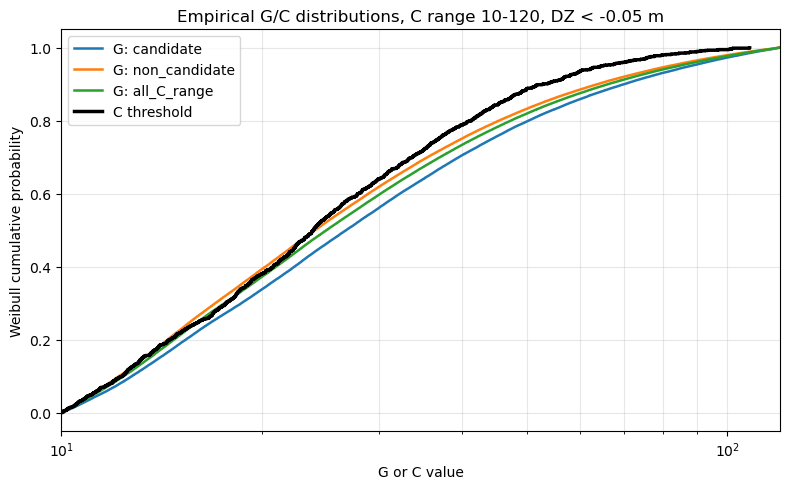

candidate cells: 103156
non-candidate cells: 170046


In [11]:
C_MIN = 10      # try 5 or 10
C_MAX = 120
DZ_THRESHOLD = -0.05

dem_diff_path = "/mnt/c/Users/amehedi/Downloads/thomas/dem_diff_updated.tif"

G, profile = read_raster(output_path(cfg, "topographic_driving_index", "topographic_driving_index.tif"))
dem_diff, _ = read_raster(dem_diff_path)

base = np.isfinite(G) & (G > 0)
c_range = base & (G >= C_MIN) & (G <= C_MAX)
eroded = np.isfinite(dem_diff) & (dem_diff < DZ_THRESHOLD)

candidate = c_range & eroded
non_candidate = c_range & (~candidate)

G_candidate = G[candidate]
G_non_candidate = G[non_candidate]
G_all_c_range = G[c_range]

c_table = pd.read_csv("/mnt/c/Users/amehedi/Downloads/source_area_workflow/c_samples.csv")
C_values = c_table["C"].dropna().values
C_values = C_values[(C_values >= C_MIN) & (C_values <= C_MAX)]

def weibull_cdf(values):
    x = np.sort(values[np.isfinite(values)])
    y = np.arange(1, len(x) + 1) / (len(x) + 1)
    return x, y

plt.figure(figsize=(8, 5))

for label, values in {
    "G: candidate": G_candidate,
    "G: non_candidate": G_non_candidate,
    "G: all_C_range": G_all_c_range,
    "C threshold": C_values,
}.items():
    x, y = weibull_cdf(values)
    lw = 2.5 if label == "C threshold" else 1.8
    color = "black" if label == "C threshold" else None
    plt.step(x, y, where="post", label=label, linewidth=lw, color=color)

plt.xscale("log")
plt.xlim(C_MIN, C_MAX)
plt.xlabel("G or C value")
plt.ylabel("Weibull cumulative probability")
plt.title(f"Empirical G/C distributions, C range {C_MIN}-{C_MAX}, DZ < {DZ_THRESHOLD} m")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("candidate cells:", len(G_candidate))
print("non-candidate cells:", len(G_non_candidate))